In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
import json

print('Libraries imported successfully')

Libraries imported successfully


# Load Union Footprint

In [2]:
footprint_path = (
    "/home/rhoffmann/MA/Footprint/Overlap/"
    "kids_desi_full_region_union_0p025deg.npz"
)

with np.load(footprint_path, allow_pickle=False) as saved_footprint:
    footprint_ra_deg_saved = saved_footprint["ra_deg"]
    footprint_dec_deg_saved = saved_footprint["dec_deg"]
    footprint_mask_saved = saved_footprint["footprint_mask"]
    footprint_metadata_saved = json.loads(str(saved_footprint["metadata_json"]))

assert len(footprint_ra_deg_saved) == len(footprint_dec_deg_saved)
assert len(footprint_ra_deg_saved) == np.count_nonzero(footprint_mask_saved)

print(f"NPZ erfolgreich geladen und geprueft: {len(footprint_ra_deg_saved):,} RA/DEC-Paare")
print(f"Metadaten: {footprint_metadata_saved}")
print("Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.")

NPZ erfolgreich geladen und geprueft: 1,011,432 RA/DEC-Paare
Metadaten: {'description': 'KiDS AND DESI observed/full region', 'bin_size_deg': 0.025, 'n_ra_bins': 14400, 'n_dec_bins': 440, 'full_dec_min': -6.0, 'full_dec_max': 5.0, 'n_true_bins': 1011432}
Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.


# Check Footprint

In [3]:
full_bin_size = float(footprint_metadata_saved["bin_size_deg"])

n_ra_bins = int(footprint_metadata_saved["n_ra_bins"])
n_dec_bins = int(footprint_metadata_saved["n_dec_bins"])

full_dec_min = float(
    footprint_metadata_saved["full_dec_min"]
)

full_dec_max = float(
    footprint_metadata_saved["full_dec_max"]
)

print(f"full_dec_min: {full_dec_min:.6f} deg")
print(f"full_dec_max: {full_dec_max:.6f} deg")
print(f"full_bin_size: {full_bin_size:.6f} deg")
print(f"n_ra_bins: {n_ra_bins:,}")
print(f"n_dec_bins: {n_dec_bins:,}")

full_dec_min: -6.000000 deg
full_dec_max: 5.000000 deg
full_bin_size: 0.025000 deg
n_ra_bins: 14,400
n_dec_bins: 440


In [4]:
ra_centers = (
    np.arange(n_ra_bins) + 0.5
) * full_bin_size

dec_centers = (
    full_dec_min
    + (np.arange(n_dec_bins) + 0.5) * full_bin_size
)

print(
    f"RA-Zentren: {ra_centers.min():.6f} "
    f"bis {ra_centers.max():.6f} deg"
)

print(
    f"DEC-Zentren: {dec_centers.min():.6f} "
    f"bis {dec_centers.max():.6f} deg"
)

RA-Zentren: 0.012500 bis 359.987500 deg
DEC-Zentren: -5.987500 bis 4.987500 deg


In [5]:
# Gespeicherte True-Bins rekonstruieren
true_ra_indices, true_dec_indices = np.where(
    footprint_mask_saved
)

ra_centers_from_mask = ra_centers[true_ra_indices]
dec_centers_from_mask = dec_centers[true_dec_indices]

assert np.allclose(
    ra_centers_from_mask,
    footprint_ra_deg_saved,
)

assert np.allclose(
    dec_centers_from_mask,
    footprint_dec_deg_saved,
)

print("RA/DEC-Zentren stimmen mit der gespeicherten Maske ueberein.")

RA/DEC-Zentren stimmen mit der gespeicherten Maske ueberein.


In [6]:
def filter_catalog_by_footprint(
    df,
    ra_column,
    dec_column,
    footprint_mask,
    full_bin_size,
    full_dec_min,
):
    ra = np.asarray(df[ra_column], dtype=np.float64)
    dec = np.asarray(df[dec_column], dtype=np.float64)

    valid = np.isfinite(ra) & np.isfinite(dec)

    # RA in [0, 360)
    ra_valid = np.mod(ra, 360.0)

    # Genau wie beim Erzeugen des Footprints
    ra_indices = np.floor(
        ra_valid / full_bin_size
    ).astype(np.int64)

    dec_indices = np.floor(
        (dec - full_dec_min) / full_bin_size
    ).astype(np.int64)

    n_ra_bins, n_dec_bins = footprint_mask.shape

    valid &= (
        (ra_indices >= 0)
        & (ra_indices < n_ra_bins)
        & (dec_indices >= 0)
        & (dec_indices < n_dec_bins)
    )

    footprint_selected = np.zeros(len(df), dtype=bool)

    footprint_selected[valid] = footprint_mask[
        ra_indices[valid],
        dec_indices[valid]
    ]

    # Wichtig: iloc
    return df.iloc[np.flatnonzero(footprint_selected)].copy()

# Load KiDS Data

In [7]:
kids_fits_file = "/DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz"
fits_files = [kids_fits_file]
kids_hdul = fits.open(kids_fits_file)
kids_data = kids_hdul[1].data
print(f'Loaded KiDS data from {kids_fits_file}')
print('Shape:', kids_data.shape)

Loaded KiDS data from /DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz
Shape: (40894394,)


# Filter KiDS Data

In [8]:
kids_rows_before_filter = len(kids_data)
kids_data = kids_data[kids_data['DECJ2000'] >= -15]
kids_df = pd.DataFrame(kids_data)

print(f'KiDS rows removed with DEC < -15 deg: {kids_rows_before_filter - len(kids_data):,}')
print(f'KiDS rows remaining: {len(kids_data):,}')
print(f'KiDS DataFrame shape: {kids_df.shape}')

KiDS rows removed with DEC < -15 deg: 20,423,231
KiDS rows remaining: 20,471,163
KiDS DataFrame shape: (20471163, 50)


In [9]:
kids_df_footprint = filter_catalog_by_footprint(
    kids_df,
    ra_column="RAJ2000",
    dec_column="DECJ2000",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print(
    f"KiDS objects in footprint: "
    f"{len(kids_df_footprint):,}"
)

print(
    f"KiDS objects removed by footprint: "
    f"{len(kids_df) - len(kids_df_footprint):,}"
)

KiDS objects in footprint: 20,188,547
KiDS objects removed by footprint: 282,616


In [10]:
kids_df = pd.DataFrame(kids_data[:10])
display(kids_df.head(10))
print(kids_df_footprint["Z_B"].head(20).to_list())

,THELI_NAME,RAJ2000,DECJ2000,PATCH,Level,FLUX_RADIUS,Agaper,Bgaper,SG2DPHOT,MAG_AUTO,...,PSF_e2_exp3,PSF_e1_exp4,PSF_e2_exp4,PSF_e1_exp5,PSF_e2_exp5,shear_weight_only,gold_weight_only,e1,e2,weight
0,KIDS_206p6_m3p5,206.125977,-3.961563,N_patch,1.606028e-08,2.194760,1.04,1.02,0,24.430859,...,0.0114,0.0298,-0.0174,99.0000,99.0000,0.095622,0.9,-0.219127,-0.290608,0.086060
1,KIDS_166p5_m3p5,166.787131,-3.961561,N_patch,1.419212e-08,2.289083,0.76,0.73,0,24.337156,...,99.0000,99.0000,99.0000,0.0003,0.0056,5.592556,1.0,-0.452054,0.107626,5.592556
2,KIDS_213p6_m3p5,213.529059,-3.961560,N_patch,1.621344e-08,2.139463,0.77,0.73,0,24.212248,...,-0.0162,-0.0050,-0.0054,0.0038,-0.0158,9.224947,1.0,-0.485352,0.061764,9.224947
3,KIDS_185p5_m3p5,185.395896,-3.961554,N_patch,1.648447e-08,2.844821,1.02,1.01,0,24.479443,...,99.0000,0.0261,0.0018,99.0000,99.0000,2.268958,1.0,-0.381656,-0.633715,2.268958
4,KIDS_202p6_m3p5,202.708561,-3.961551,N_patch,1.675953e-08,6.320547,1.13,1.13,0,21.123289,...,99.0000,0.0333,0.0072,-0.0003,-0.0033,15.453700,1.0,0.063528,0.019502,15.453700
5,KIDS_192p5_m3p5,192.664470,-3.961547,N_patch,1.595112e-08,2.181150,0.81,0.76,0,22.556332,...,-0.0119,0.0290,0.0013,0.0109,0.0041,13.755224,1.0,0.634960,-0.116970,13.755224
6,KIDS_209p6_m3p5,209.503696,-3.961545,N_patch,1.635181e-08,2.856561,0.77,0.72,0,24.069933,...,99.0000,-0.0178,-0.0075,0.0074,-0.0346,2.570638,0.8,0.539179,-0.000728,2.056511
7,KIDS_211p6_m3p5,211.243906,-3.961545,N_patch,1.631785e-08,2.249372,0.75,0.71,0,24.491802,...,0.0100,0.0146,-0.0009,99.0000,99.0000,0.638309,0.8,0.191577,0.554511,0.510647
8,KIDS_199p6_m3p5,199.106318,-3.961544,N_patch,1.567321e-08,2.631182,0.81,0.73,0,23.879148,...,0.0131,99.0000,99.0000,0.0175,-0.0012,11.302017,1.0,0.394700,-0.565559,11.302017
9,KIDS_196p5_m3p5,196.376354,-3.961543,N_patch,1.456847e-08,2.901005,1.03,1.01,0,24.251553,...,99.0000,0.0218,-0.0180,0.0344,-0.0046,3.100717,1.0,0.295218,-0.209102,3.100717


[1.2, 0.53, 1.53, 0.8, 0.71, 0.33, 1.36, 0.9, 0.39, 0.65, 0.81, 0.78, 0.79, 0.65, 1.07, 0.54, 1.05, 0.46, 0.96, 0.25]


# Load DESI Data

In [11]:
# =========================
# BGS ANY
# =========================

with fits.open('/DATA02/rhoffmann/DESI/BGS ANY/BGS ANY.fits') as hdul:
    bgs_data = hdul[1].data

    bgs_dict = {}

    for name in bgs_data.names:
        column = bgs_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        bgs_dict[name] = np.array(column)

    bgs_any_df = pd.DataFrame(bgs_dict)

print("BGS ANY:", bgs_any_df.shape)


# =========================
# LRG
# =========================

with fits.open('/DATA02/rhoffmann/DESI/LRG/LRG.fits') as hdul:
    lrg_data = hdul[1].data

    lrg_dict = {}

    for name in lrg_data.names:
        column = lrg_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        lrg_dict[name] = np.array(column)

    lrg_df = pd.DataFrame(lrg_dict)

print("LRG:", lrg_df.shape)

BGS ANY: (1027650, 18)
LRG: (515770, 13)


In [12]:
print("\nBig-Endian-Spalten in BGS:")
for column in bgs_any_df.columns:
    dtype = bgs_any_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)

print("\nBig-Endian-Spalten in LRG:")
for column in lrg_df.columns:
    dtype = lrg_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)


Big-Endian-Spalten in BGS:

Big-Endian-Spalten in LRG:


# Filter DESI Data

In [13]:
bgs_any_footprint_df = filter_catalog_by_footprint(
    bgs_any_df,
    ra_column="desi_dr1_lss_v1_5_bgs_any_dat.ra",
    dec_column="desi_dr1_lss_v1_5_bgs_any_dat.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("BGS vorher:", len(bgs_any_df))
print("BGS nach Footprint:", len(bgs_any_footprint_df))


BGS vorher: 1027650
BGS nach Footprint: 577879


In [14]:
lrg_footprint_df = filter_catalog_by_footprint(
    lrg_df,
    ra_column="desi_dr1_lss_v1_5_lrg_dat.ra",
    dec_column="desi_dr1_lss_v1_5_lrg_dat.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("LRG vorher:", len(lrg_df))
print("LRG nach Footprint:", len(lrg_footprint_df))

LRG vorher: 515770
LRG nach Footprint: 288692


In [15]:
display(bgs_any_df.head(10))
display(lrg_df.head(10))

,desi_dr1_lss_v1_5_bgs_any_dat.targetid,desi_dr1_lss_v1_5_bgs_any_dat.z,desi_dr1_lss_v1_5_bgs_any_dat.ntile,desi_dr1_lss_v1_5_bgs_any_dat.ra,desi_dr1_lss_v1_5_bgs_any_dat.dec,desi_dr1_lss_v1_5_bgs_any_dat.photsys,desi_dr1_lss_v1_5_bgs_any_dat.frac_tlobs_tiles,desi_dr1_lss_v1_5_bgs_any_dat.weight_zfail,desi_dr1_lss_v1_5_bgs_any_dat.weight,desi_dr1_lss_v1_5_bgs_any_dat.weight_comp,desi_dr1_lss_v1_5_bgs_any_dat.weight_sys,desi_dr1_lss_v1_5_bgs_any_dat.flux_g_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_r_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_z_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_w1_dered,desi_dr1_lss_v1_5_bgs_any_dat.flux_w2_dered,desi_dr1_lss_v1_5_bgs_any_dat.nx,desi_dr1_lss_v1_5_bgs_any_dat.weight_fkp
0,39627642084789536,0.302015,1,127.404466,-5.986855,S,0.985703,1.000000,0.419068,1.0,1.0,6.116484,25.559881,53.221317,69.084984,46.982098,0.002449,0.055123
1,39627642084789952,0.359715,1,127.418185,-5.975900,S,0.985703,1.001585,0.839464,2.0,1.0,2.635645,10.894744,21.935942,27.790562,19.837645,0.001441,0.090206
2,39627642088981286,0.082816,1,127.556968,-5.937155,S,0.985703,1.001294,0.419611,1.0,1.0,19.786264,33.849583,51.113781,41.900726,26.596487,0.023028,0.006165
3,39627642088981352,0.353340,1,127.559128,-5.990249,S,0.985703,1.003566,2.102812,5.0,1.0,3.190038,14.313684,33.791916,56.791729,38.210106,0.001441,0.090206
4,39627642088982139,0.356098,1,127.587646,-5.971131,S,0.985703,1.000000,0.838136,2.0,1.0,8.712421,33.903305,71.832222,104.307724,71.601875,0.001441,0.090206
5,39627642088984585,0.032162,1,127.681697,-5.937755,S,0.985703,1.002479,0.840214,2.0,1.0,42.189106,60.564434,70.121040,-10.677300,-17.857647,0.051039,0.002791
6,39627642088984813,0.175009,1,127.691605,-5.986173,S,0.985703,1.000000,0.838136,2.0,1.0,10.380540,19.050573,29.618589,25.051371,16.632957,0.008768,0.016032
7,39627642088985356,0.191770,1,127.713399,-5.933927,S,0.985703,1.000000,0.419068,1.0,1.0,21.949341,41.463440,65.220070,65.187569,51.757973,0.007611,0.018424
8,39627642088986177,0.163207,1,127.743969,-5.897843,S,0.985703,1.002536,0.420131,1.0,1.0,13.812540,26.652590,42.469215,38.996716,24.205725,0.009573,0.014703
9,39627642088986840,0.163253,1,127.771028,-5.918813,S,0.985703,1.000000,0.838136,2.0,1.0,6.961936,18.219381,32.975201,25.242237,16.024746,0.009573,0.014703


,desi_dr1_lss_v1_5_lrg_dat.targetid,desi_dr1_lss_v1_5_lrg_dat.z,desi_dr1_lss_v1_5_lrg_dat.ntile,desi_dr1_lss_v1_5_lrg_dat.ra,desi_dr1_lss_v1_5_lrg_dat.dec,desi_dr1_lss_v1_5_lrg_dat.photsys,desi_dr1_lss_v1_5_lrg_dat.frac_tlobs_tiles,desi_dr1_lss_v1_5_lrg_dat.weight_zfail,desi_dr1_lss_v1_5_lrg_dat.weight_sys,desi_dr1_lss_v1_5_lrg_dat.weight,desi_dr1_lss_v1_5_lrg_dat.weight_comp,desi_dr1_lss_v1_5_lrg_dat.nx,desi_dr1_lss_v1_5_lrg_dat.weight_fkp
0,39627642084787603,0.809332,1,127.331994,-5.913763,S,0.888268,1.009297,0.995586,0.611313,1.0,0.000299,0.250469
1,39627642084789818,0.693160,1,127.413705,-5.907806,S,0.888268,1.001131,0.981486,1.195559,2.0,0.000267,0.272466
2,39627642093176735,0.432908,2,127.863737,-5.957493,S,0.937931,1.000000,0.972920,1.469349,2.0,0.000374,0.210814
3,39627642093178130,0.942167,2,127.926200,-5.891132,S,0.937931,1.002733,0.998015,0.755684,1.0,0.000212,0.320591
4,39627642097369566,0.515453,2,128.048670,-5.947349,S,0.937931,1.000000,0.983710,0.742822,1.0,0.000363,0.216011
5,39627642097370424,0.767572,2,128.078599,-5.976601,S,0.937931,1.000000,0.993249,2.250075,3.0,0.000384,0.206578
6,39627642097370758,0.433292,2,128.091401,-5.948706,S,0.937931,1.000000,0.983710,1.485644,2.0,0.000374,0.210814
7,39627642097372183,0.567776,2,128.147980,-5.972916,S,0.937931,1.000000,0.983710,0.742822,1.0,0.000391,0.203588
8,39627642101566397,0.829045,2,128.396630,-5.983671,S,0.937931,1.005718,0.993142,0.754232,1.0,0.000385,0.206258
9,39627642105758960,0.952197,2,128.584453,-5.998511,S,0.937931,1.006176,0.993142,0.754576,1.0,0.000199,0.334309


# Display Data

In [16]:
ra_bins = np.linspace(-180, 180, 3601)
dec_bins = np.linspace(-90, 90, 1801)
counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

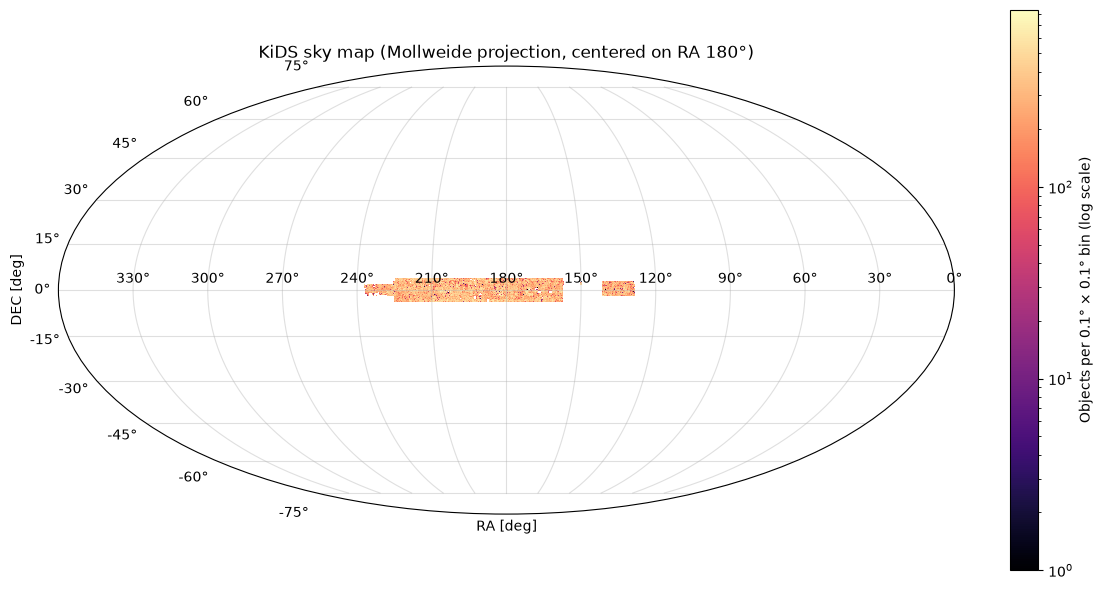

In [17]:
from matplotlib.colors import LogNorm

ra_bins = np.linspace(-180, 180, 3601)
dec_bins = np.linspace(-90, 90, 1801)
counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for start in range(0, len(kids_df_footprint), 1_000_000):
    chunk = kids_df_footprint[start:start + 1_000_000]
    ra_longitude = -((chunk['RAJ2000'] % 360) - 180)
    counts += np.histogram2d(
        ra_longitude,
        chunk['DECJ2000'],
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS sky map (Mollweide projection, centered on RA 180°)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

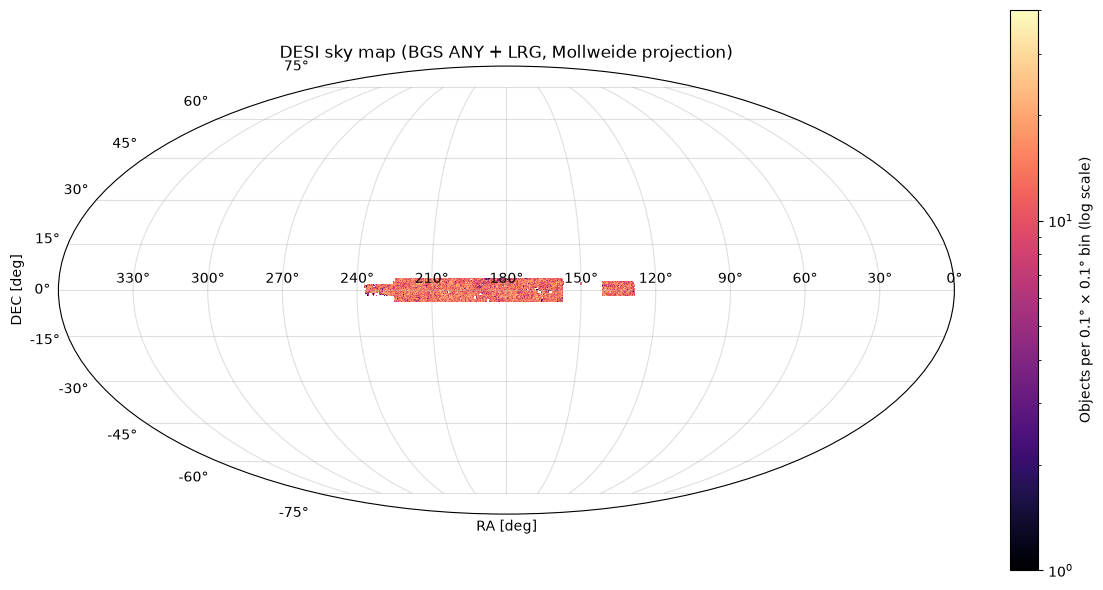

In [18]:
desi_counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for catalog in (bgs_any_footprint_df, lrg_footprint_df):
    ra_column = next(column for column in catalog.columns if column.lower().endswith('.ra'))
    dec_column = next(column for column in catalog.columns if column.lower().endswith('.dec'))
    ra_longitude = -((catalog[ra_column].to_numpy() % 360) - 180)
    desi_counts += np.histogram2d(
        ra_longitude,
        catalog[dec_column].to_numpy(),
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(desi_counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('DESI sky map (BGS ANY + LRG, Mollweide projection)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

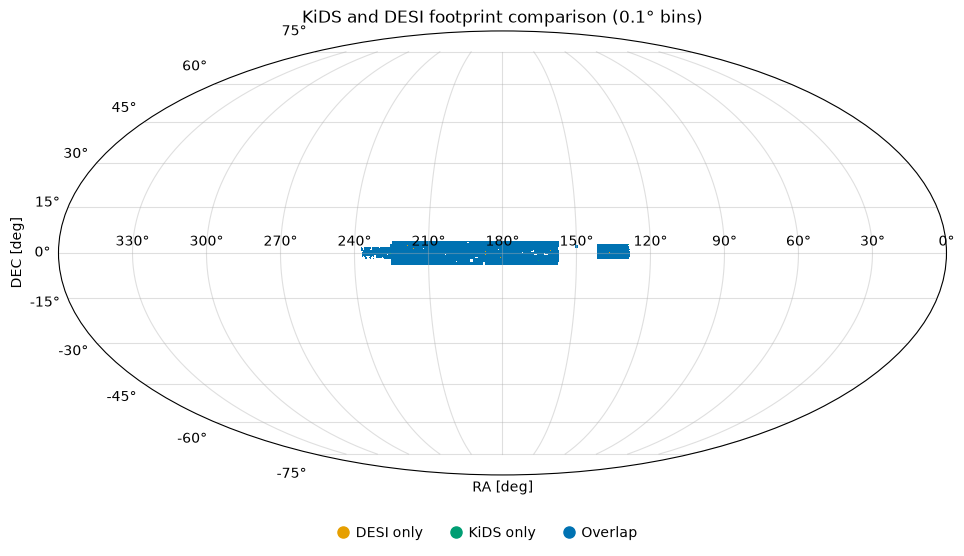

KiDS fully covered by DESI: No
Overlapping bins: 64,462
KiDS-only bins: 91
DESI-only bins: 69


In [19]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

kids_occupied = counts > 0
desi_occupied = desi_counts > 0
shared = kids_occupied & desi_occupied
kids_only = kids_occupied & ~desi_occupied
desi_only = desi_occupied & ~kids_occupied

comparison = np.zeros_like(counts, dtype=np.uint8)
comparison[desi_only] = 1
comparison[kids_only] = 2
comparison[shared] = 3

comparison_cmap = ListedColormap(['#e69f00', '#009e73', '#0072b2'])
comparison_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], comparison_cmap.N)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_equal(comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS and DESI footprint comparison (0.1° bins)')

legend_items = [
    Line2D([], [], marker='o', linestyle='None', color='#e69f00', markersize=8,
           label='DESI only'),
    Line2D([], [], marker='o', linestyle='None', color='#009e73', markersize=8,
           label='KiDS only'),
    Line2D([], [], marker='o', linestyle='None', color='#0072b2', markersize=8,
           label='Overlap'),
]
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.14)
plt.show()

print(f'KiDS fully covered by DESI: {"Yes" if not np.any(kids_only) else "No"}')
print(f'Overlapping bins: {np.count_nonzero(shared):,}')
print(f'KiDS-only bins: {np.count_nonzero(kids_only):,}')
print(f'DESI-only bins: {np.count_nonzero(desi_only):,}')

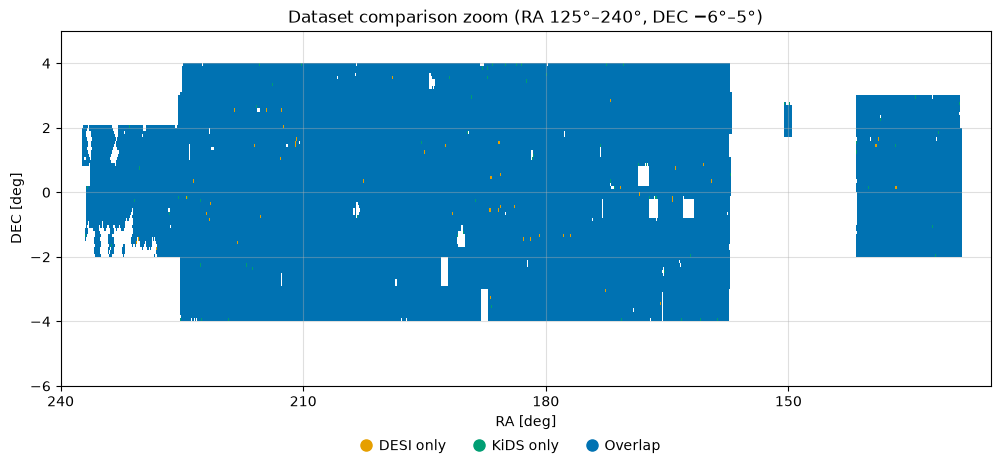

Non-empty bins in zoom: 64,622


In [20]:
ra_longitude_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
ra_centers = (180 - ra_longitude_centers) % 360
dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2

ra_indices = np.flatnonzero((ra_centers >= 120) & (ra_centers <= 240))
dec_indices = np.flatnonzero((dec_centers >= -10) & (dec_centers <= 10))

zoom_ra_edges = 180 - ra_bins[ra_indices[0]:ra_indices[-1] + 2]
zoom_dec_edges = dec_bins[dec_indices[0]:dec_indices[-1] + 2]
zoom_comparison = comparison[np.ix_(ra_indices, dec_indices)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    zoom_ra_edges,
    zoom_dec_edges,
    np.ma.masked_equal(zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('Dataset comparison zoom (RA 125°–240°, DEC −6°–5°)')
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()
print(f'Non-empty bins in zoom: {np.count_nonzero(zoom_comparison):,}')

# Tomobins KiDS

In [21]:
# KiDS tomographic source bins
kids_tomo_bins = {}

for tomo_bin in sorted(kids_df_footprint["TOMOBIN"].dropna().unique()):

    kids_tomo_bins[int(tomo_bin)] = kids_df_footprint[
        kids_df_footprint["TOMOBIN"] == tomo_bin
    ].copy()

    print(
        f"KiDS TOMOBIN {int(tomo_bin)}: "
        f"{len(kids_tomo_bins[int(tomo_bin)])} sources"
    )

KiDS TOMOBIN 1: 3683163 sources
KiDS TOMOBIN 2: 3779080 sources
KiDS TOMOBIN 3: 3449734 sources
KiDS TOMOBIN 4: 3367244 sources
KiDS TOMOBIN 5: 3105132 sources
KiDS TOMOBIN 6: 2804194 sources


In [22]:
print(
    kids_df_footprint
    .groupby("TOMOBIN")["Z_B"]
    .agg(["count", "min", "max", "median", "mean"])
)

           count   min   max  median      mean
TOMOBIN                                       
1        3683163  0.11  0.42    0.31  0.297212
2        3779080  0.43  0.58    0.51  0.507719
3        3449734  0.59  0.71    0.64  0.646761
4        3367244  0.72  0.90    0.81  0.807634
5        3105132  0.91  1.14    1.01  1.014071
6        2804194  1.15  2.00    1.34  1.384357


In [23]:
print([
    col for col in bgs_any_footprint_df.columns
    if "z" in col.lower() or "redshift" in col.lower()
])

print([
    col for col in lrg_footprint_df.columns
    if "z" in col.lower() or "redshift" in col.lower()
])

['desi_dr1_lss_v1_5_bgs_any_dat.z', 'desi_dr1_lss_v1_5_bgs_any_dat.weight_zfail', 'desi_dr1_lss_v1_5_bgs_any_dat.flux_z_dered']
['desi_dr1_lss_v1_5_lrg_dat.z', 'desi_dr1_lss_v1_5_lrg_dat.weight_zfail']


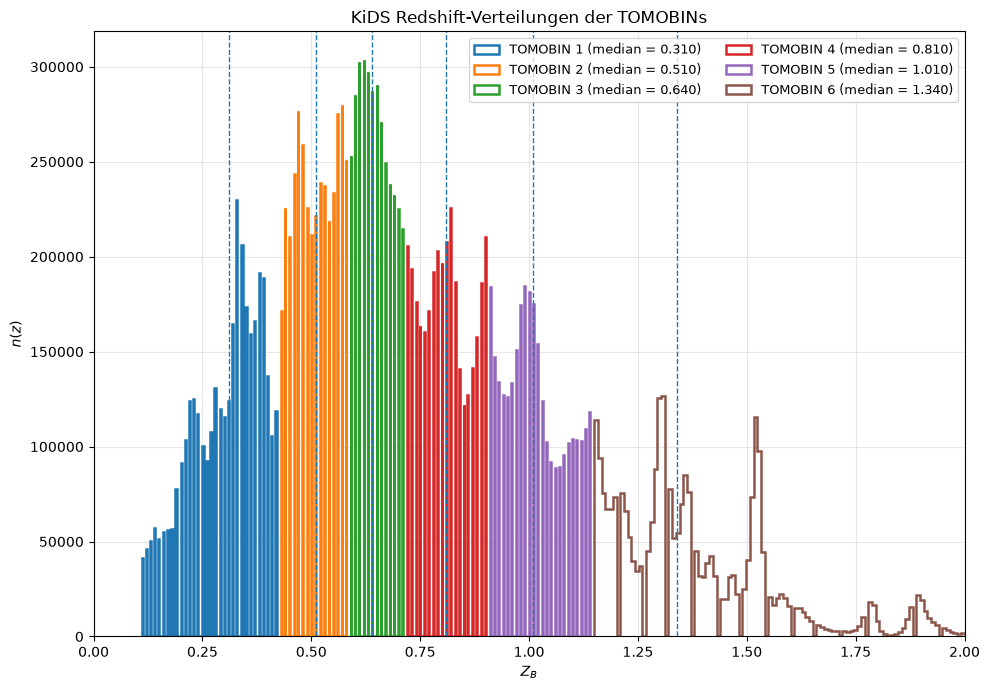

In [24]:
# ============================================================
# KiDS Redshift-Verteilungen der TOMOBINs
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 7))


for tomo_bin in sorted(
    kids_df_footprint["TOMOBIN"].dropna().unique()
):

    # --------------------------------------------------------
    # Quellen dieses TOMOBINs auswählen
    # --------------------------------------------------------

    tomo_df = kids_df_footprint[
        kids_df_footprint["TOMOBIN"] == tomo_bin
    ]


    # --------------------------------------------------------
    # Gültige Z_B-Werte
    # --------------------------------------------------------

    z = tomo_df["Z_B"].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]


    if len(z) == 0:
        continue


    # --------------------------------------------------------
    # Redshift-Verteilung
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"TOMOBIN {int(tomo_bin)} "
            f"(median = {np.median(z):.3f})"
        ),
    )


    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$Z_B$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "KiDS Redshift-Verteilungen der TOMOBINs"
)

plt.xlim(
    0,
    2.0
)

plt.grid(
    True,
    which="both",
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
    ncol=2,
)

plt.tight_layout()

plt.show()

# Tomobins DESI

In [25]:
# ============================================================
# DESI BGS tomographic lens bins
# ============================================================

BGS_Z_COLUMN = "desi_dr1_lss_v1_5_bgs_any_dat.z"

bgs_z_bins = {
    "BGS 0.1-0.2": (0.1, 0.2),
    "BGS 0.2-0.3": (0.2, 0.3),
    "BGS 0.3-0.4": (0.3, 0.4),
}

bgs_tomo_bins = {}

for tomo_name, (z_min, z_max) in bgs_z_bins.items():

    mask = (
        np.isfinite(bgs_any_footprint_df[BGS_Z_COLUMN])
        & (bgs_any_footprint_df[BGS_Z_COLUMN] >= z_min)
        & (bgs_any_footprint_df[BGS_Z_COLUMN] < z_max)
    )

    bgs_tomo_bins[tomo_name] = (
        bgs_any_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name}: "
        f"{len(bgs_tomo_bins[tomo_name])} lenses"
    )

BGS 0.1-0.2: 165717 lenses
BGS 0.2-0.3: 183190 lenses
BGS 0.3-0.4: 115895 lenses


In [26]:
# ============================================================
# DESI LRG tomographic lens bins
# ============================================================

LRG_Z_COLUMN = "desi_dr1_lss_v1_5_lrg_dat.z"

lrg_z_bins = {
    "LRG 0.4-0.6": (0.4, 0.6),
    "LRG 0.6-0.8": (0.6, 0.8),
}

lrg_tomo_bins = {}

for tomo_name, (z_min, z_max) in lrg_z_bins.items():

    mask = (
        np.isfinite(lrg_footprint_df[LRG_Z_COLUMN])
        & (lrg_footprint_df[LRG_Z_COLUMN] >= z_min)
        & (lrg_footprint_df[LRG_Z_COLUMN] < z_max)
    )

    lrg_tomo_bins[tomo_name] = (
        lrg_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name}: "
        f"{len(lrg_tomo_bins[tomo_name])} lenses"
    )

LRG 0.4-0.6: 67741 lenses
LRG 0.6-0.8: 104687 lenses


In [27]:
print("\nBGS tomographic bins:")
for name, df in bgs_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[BGS_Z_COLUMN].median():.3f}, "
        f"mean z = {df[BGS_Z_COLUMN].mean():.3f}"
    )


print("\nLRG tomographic bins:")
for name, df in lrg_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[LRG_Z_COLUMN].median():.3f}, "
        f"mean z = {df[LRG_Z_COLUMN].mean():.3f}"
    )


BGS tomographic bins:
BGS 0.1-0.2     N =   165717, median z = 0.152, mean z = 0.152
BGS 0.2-0.3     N =   183190, median z = 0.250, mean z = 0.249
BGS 0.3-0.4     N =   115895, median z = 0.343, mean z = 0.345

LRG tomographic bins:
LRG 0.4-0.6     N =    67741, median z = 0.516, mean z = 0.510
LRG 0.6-0.8     N =   104687, median z = 0.711, mean z = 0.707


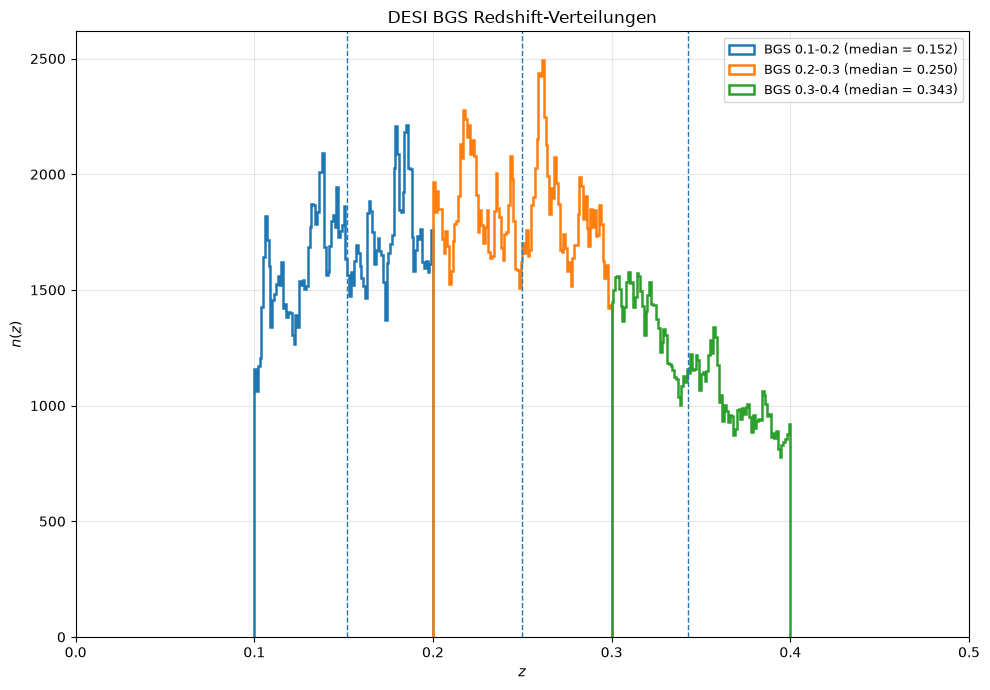

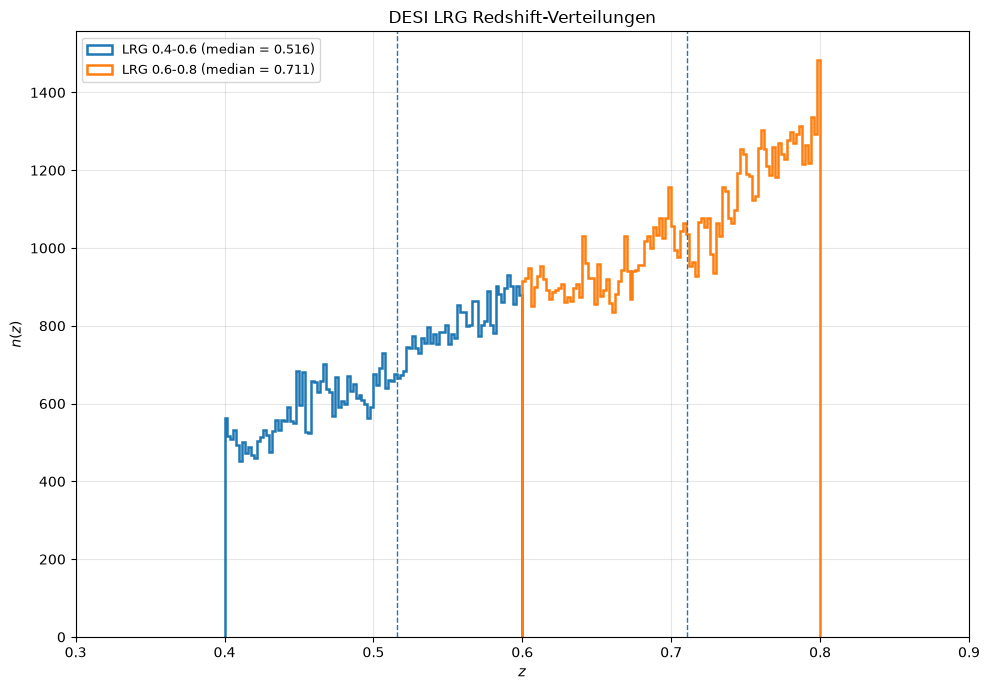

In [28]:
# ============================================================
# DESI BGS + LRG Redshift-Verteilungen
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. BGS Redshift-Verteilungen
# ============================================================

plt.figure(figsize=(10, 7))

for tomo_name in bgs_tomo_bins:

    tomo_df = bgs_tomo_bins[tomo_name]

    # --------------------------------------------------------
    # Gültige Redshifts
    # --------------------------------------------------------

    z = tomo_df[BGS_Z_COLUMN].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]

    if len(z) == 0:
        continue

    # --------------------------------------------------------
    # Histogramm
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"{tomo_name} "
            f"(median = {np.median(z):.3f})"
        ),
    )

    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$z$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "DESI BGS Redshift-Verteilungen"
)

plt.xlim(
    0.0,
    0.5
)

plt.grid(
    True,
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
)

plt.tight_layout()

plt.show()


# ============================================================
# 2. LRG Redshift-Verteilungen
# ============================================================

plt.figure(figsize=(10, 7))

for tomo_name in lrg_tomo_bins:

    tomo_df = lrg_tomo_bins[tomo_name]

    # --------------------------------------------------------
    # Gültige Redshifts
    # --------------------------------------------------------

    z = tomo_df[LRG_Z_COLUMN].to_numpy(
        dtype=np.float64
    )

    z = z[np.isfinite(z)]

    if len(z) == 0:
        continue

    # --------------------------------------------------------
    # Histogramm
    # --------------------------------------------------------

    plt.hist(
        z,
        bins=100,
        density=False,
        histtype="step",
        linewidth=1.8,
        label=(
            f"{tomo_name} "
            f"(median = {np.median(z):.3f})"
        ),
    )

    # --------------------------------------------------------
    # Median markieren
    # --------------------------------------------------------

    plt.axvline(
        np.median(z),
        linestyle="--",
        linewidth=1,
    )


# ============================================================
# Plot-Einstellungen
# ============================================================

plt.xlabel(
    r"$z$"
)

plt.ylabel(
    r"$n(z)$"
)

plt.title(
    "DESI LRG Redshift-Verteilungen"
)

plt.xlim(
    0.3,
    0.9
)

plt.grid(
    True,
    linestyle="-",
    alpha=0.3,
)

plt.legend(
    fontsize=9,
)

plt.tight_layout()

plt.show()

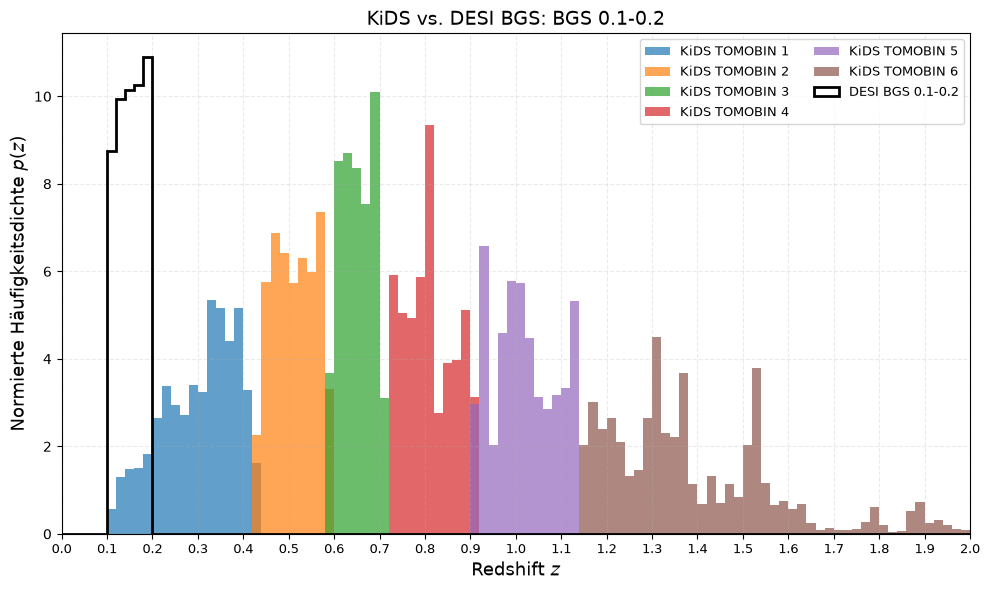

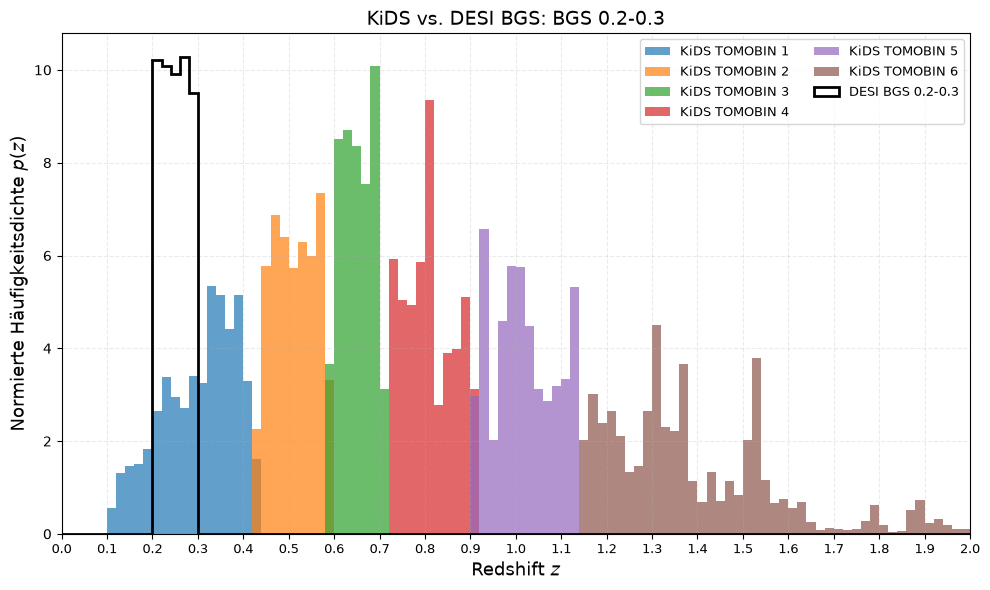

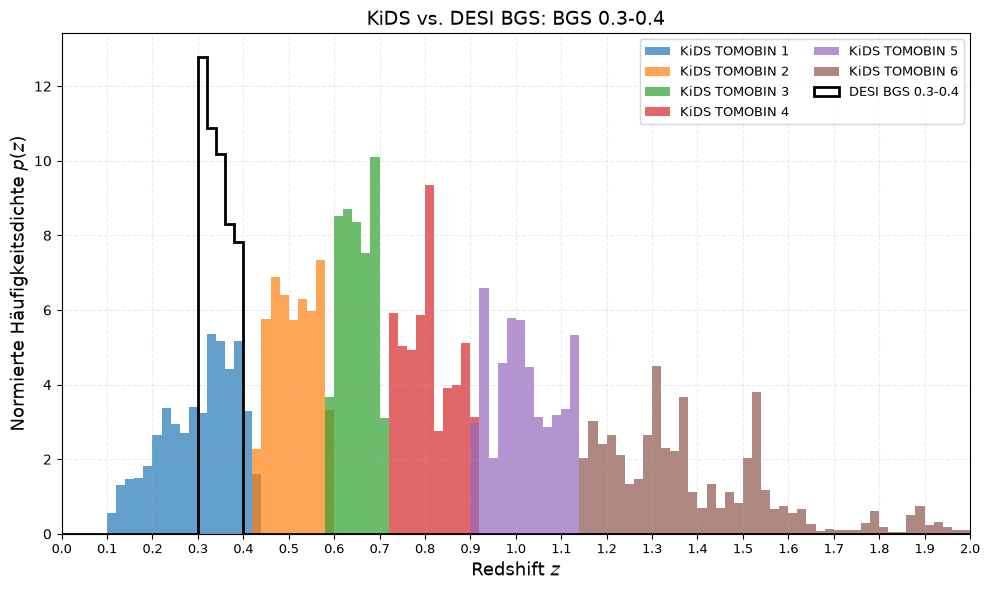

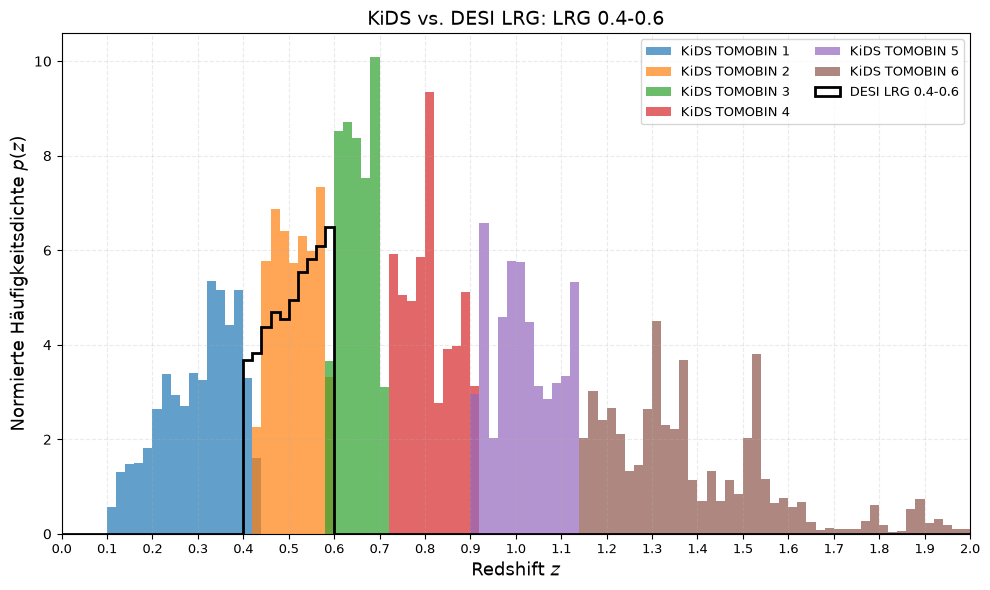

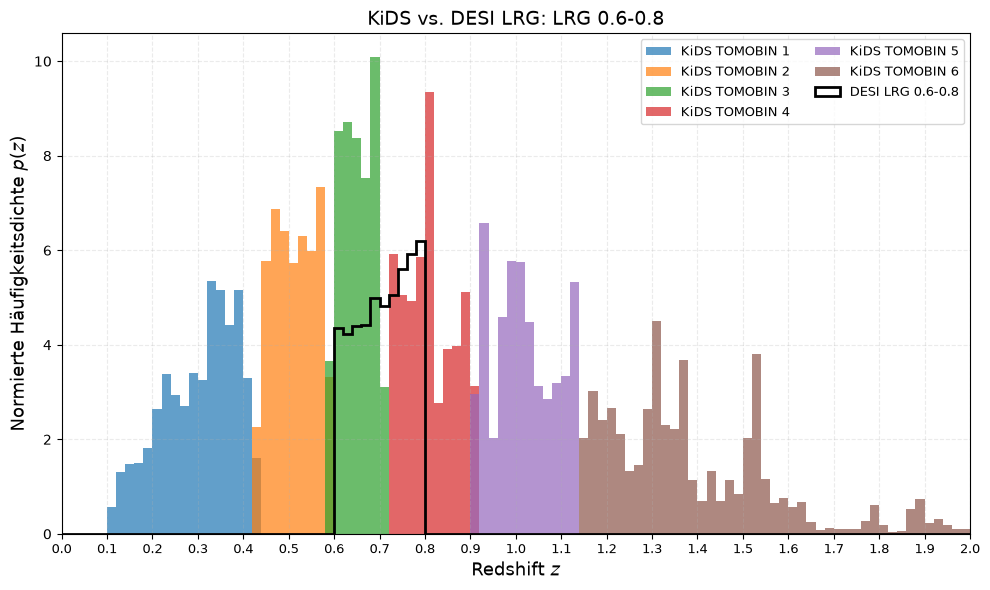

In [29]:
# ============================================================
# Separate Plots: Jede DESI-Lens-Population + alle KiDS-Bins
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Einstellungen
# ============================================================

n_bins = 100
hist_range = (0.0, 2.0)
alpha_fill = 0.25


# ============================================================
# Funktion: Alle KiDS-Bins + eine DESI-Population plotten
# ============================================================

def plot_kids_vs_desi(
    tomo_name,
    tomo_df,
    z_column,
    lens_label
):
    fig, ax = plt.subplots(figsize=(10, 6))

    # --------------------------------------------------------
    # 1. Alle KiDS-Tomografiebins
    # --------------------------------------------------------

    for i, kids_bin in enumerate(kids_tomo_bins):

        kids_df = kids_df_footprint[
            kids_df_footprint["TOMOBIN"] == kids_bin
        ]

        z_kids = kids_df["Z_B"].to_numpy(dtype=np.float64)
        z_kids = z_kids[np.isfinite(z_kids)]

        if len(z_kids) == 0:
            continue

        ax.hist(
            z_kids,
            bins=n_bins,
            range=hist_range,
            density=True,
            histtype="stepfilled",
            linewidth=1.3,
            alpha=0.7,
            label=f"KiDS TOMOBIN {int(kids_bin)}",
            zorder=1,
        )

    # --------------------------------------------------------
    # 2. Eine DESI-Lens-Population
    # --------------------------------------------------------

    z_lens = tomo_df[z_column].to_numpy(dtype=np.float64)
    z_lens = z_lens[np.isfinite(z_lens)]

    if len(z_lens) > 0:

        ax.hist(
            z_lens,
            bins=n_bins,
            range=hist_range,
            density=True,
            histtype="step",
            linewidth=2.0,
            color="black",
            label=f"DESI {tomo_name}",
            zorder=3,
        )

    # --------------------------------------------------------
    # 3. Plot-Einstellungen
    # --------------------------------------------------------

    ax.set_xlabel(r"Redshift $z$", fontsize=13)
    ax.set_ylabel(r"Normierte Häufigkeitsdichte $p(z)$", fontsize=13)

    ax.set_title(
        f"KiDS vs. {lens_label}: {tomo_name}",
        fontsize=14,
    )

    ax.set_xlim(*hist_range)
    # X-Achse: Schritte von 0.1
    ax.set_xticks(np.arange(0.0, 2.01, 0.1))
    ax.tick_params(axis="x", labelsize=9)

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25,
    )

    ax.legend(
        fontsize=9,
        ncol=2,
        frameon=True,
    )

    fig.tight_layout()
    plt.show()


# ============================================================
# 3. Separater Plot für jeden BGS-Bin
# ============================================================

for i, tomo_name in enumerate(bgs_tomo_bins):

    plot_kids_vs_desi(
        tomo_name=tomo_name,
        tomo_df=bgs_tomo_bins[tomo_name],
        z_column=BGS_Z_COLUMN,
        lens_label="DESI BGS",
    )


# ============================================================
# 4. Separater Plot für jeden LRG-Bin
# ============================================================

for i, tomo_name in enumerate(lrg_tomo_bins):

    plot_kids_vs_desi(
        tomo_name=tomo_name,
        tomo_df=lrg_tomo_bins[tomo_name],
        z_column=LRG_Z_COLUMN,
        lens_label="DESI LRG",
    )

# G2L Lensing Profiles with TreeCorr (no correction applyed)

Erstelle KiDS Source-Kataloge
KiDS TOMOBIN 1: 3,683,163 Quellen (Z_B ~ 0.11-0.42)
KiDS TOMOBIN 2: 3,779,080 Quellen (Z_B ~ 0.43-0.58)
KiDS TOMOBIN 3: 3,449,734 Quellen (Z_B ~ 0.59-0.71)
KiDS TOMOBIN 4: 3,367,244 Quellen (Z_B ~ 0.72-0.90)
KiDS TOMOBIN 5: 3,105,132 Quellen (Z_B ~ 0.91-1.14)
KiDS TOMOBIN 6: 2,804,194 Quellen (Z_B ~ 1.15-2.00)


Erstelle DESI BGS Lens-Kataloge
BGS 0.1-0.2: 165,717 Lenses (z = 0.1-0.2)
BGS 0.2-0.3: 183,190 Lenses (z = 0.2-0.3)
BGS 0.3-0.4: 115,895 Lenses (z = 0.3-0.4)


Erstelle DESI LRG Lens-Kataloge
LRG 0.4-0.6: 67,741 Lenses (z = 0.4-0.6)
LRG 0.6-0.8: 104,687 Lenses (z = 0.6-0.8)


Median-Redshifts der KiDS Source-TOMOBINs
KiDS TOMOBIN 1: median z = 0.3100
KiDS TOMOBIN 2: median z = 0.5100
KiDS TOMOBIN 3: median z = 0.6400
KiDS TOMOBIN 4: median z = 0.8100
KiDS TOMOBIN 5: median z = 1.0100
KiDS TOMOBIN 6: median z = 1.3400


Median-Redshifts der DESI BGS Lens-TOMOBINs
BGS 0.1-0.2: median z = 0.1520
BGS 0.2-0.3: median z = 0.2498
BGS 0.3-0.4: median z = 0

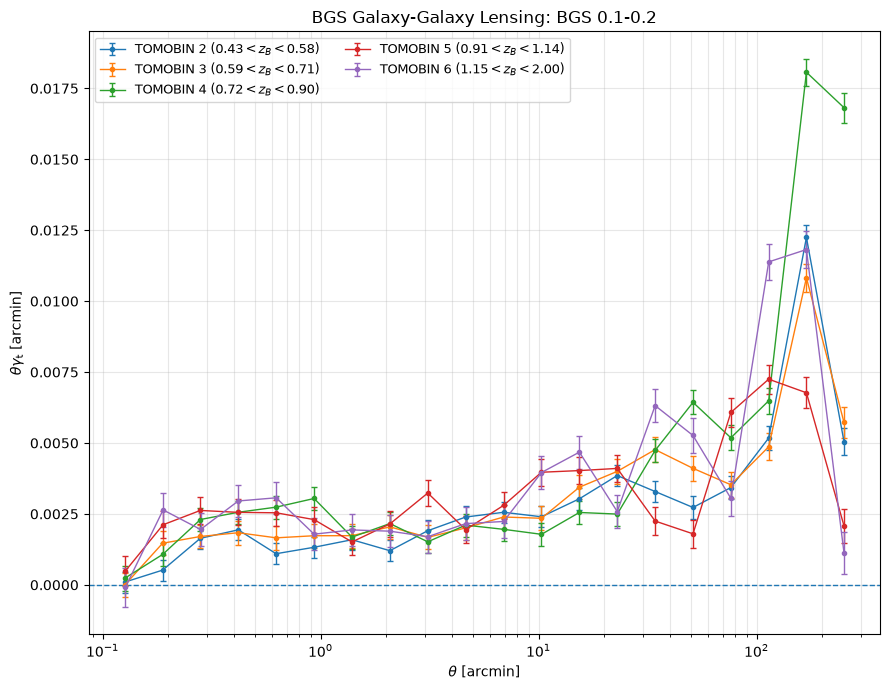

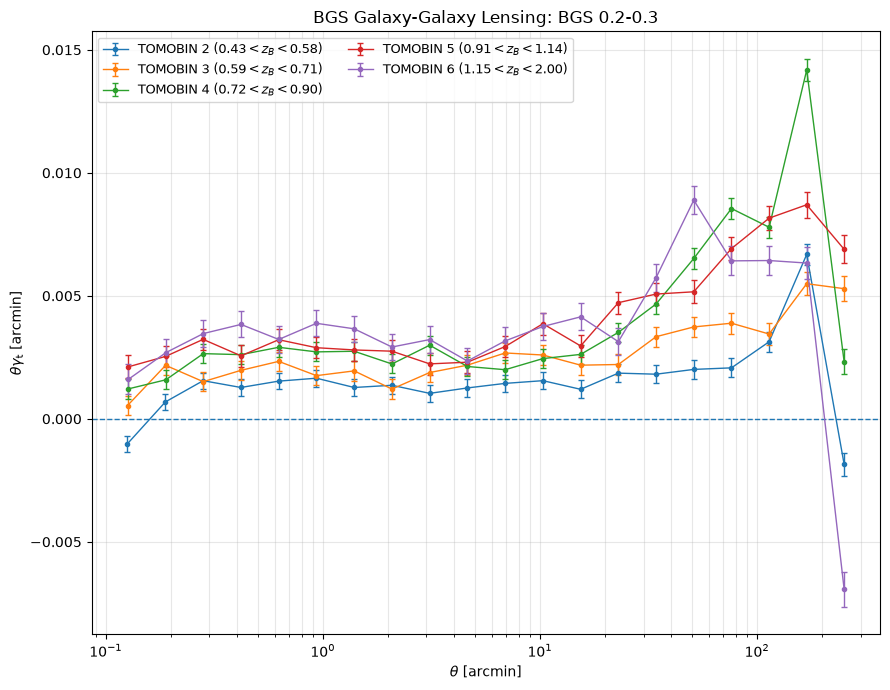

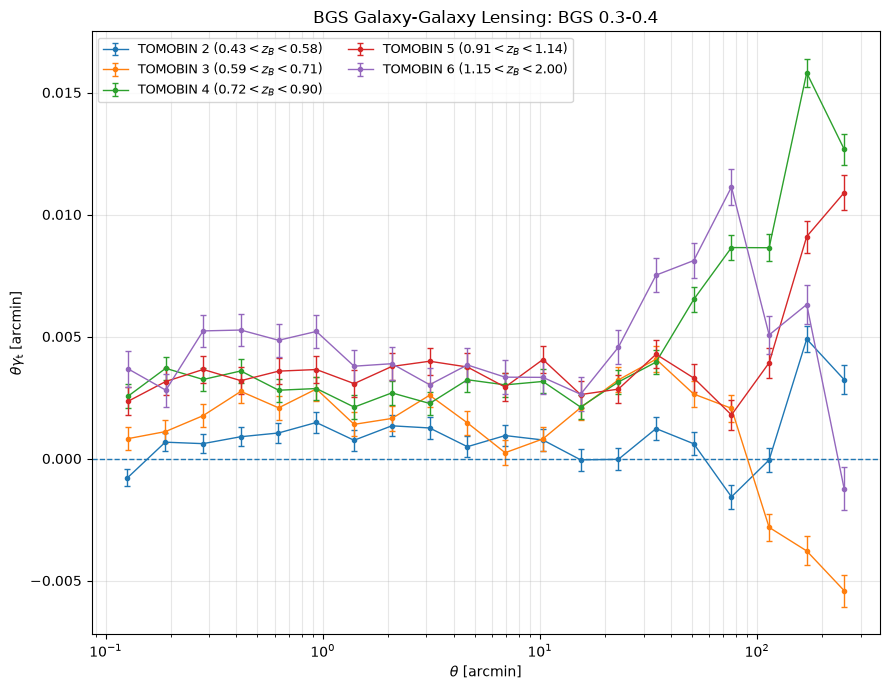

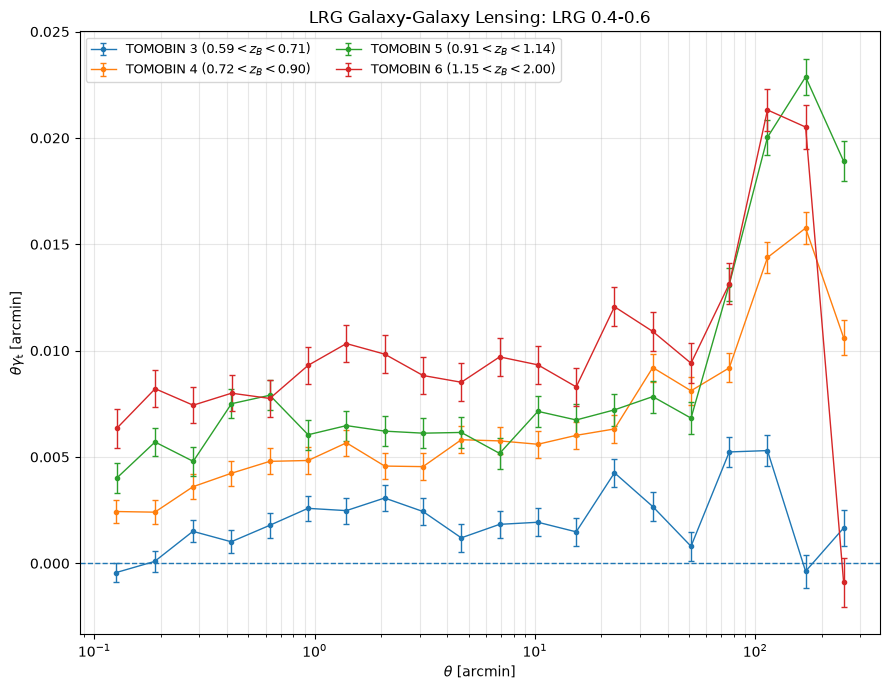

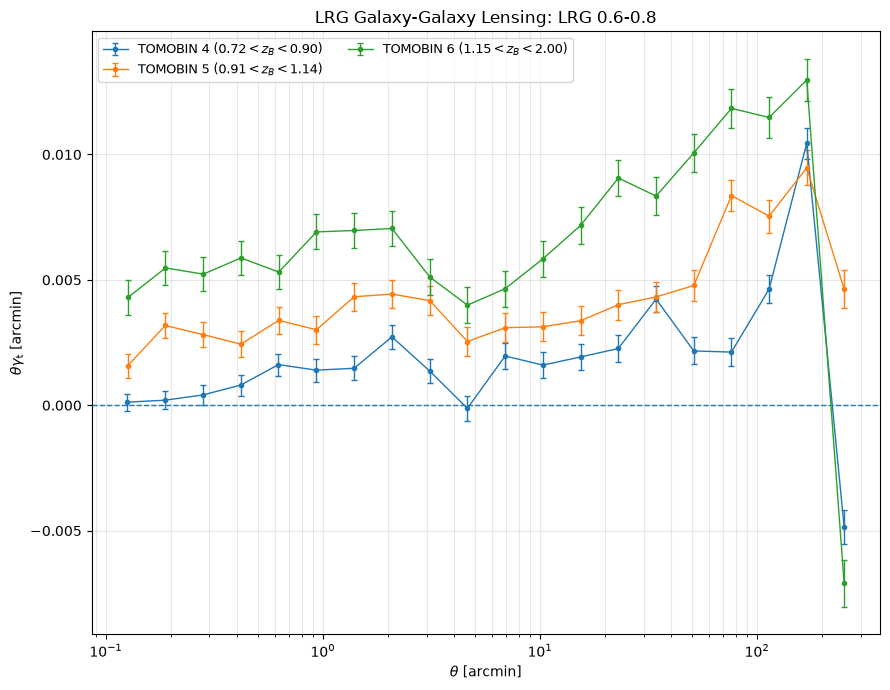

In [30]:
import numpy as np
import treecorr
import matplotlib.pyplot as plt


# ============================================================
# TreeCorr-Konfiguration
# ============================================================

config = {
    "nbins": 20,
    "min_sep": 0.1,
    "max_sep": 300.0,
    "sep_units": "arcmin",
}


# ============================================================
# Definition der Tomographie
# ============================================================


# ------------------------------------------------------------
# KiDS Source TOMOBINs
# ------------------------------------------------------------

kids_tomo_bins = {
    1: (0.11, 0.42),
    2: (0.43, 0.58),
    3: (0.59, 0.71),
    4: (0.72, 0.90),
    5: (0.91, 1.14),
    6: (1.15, 2.00),
}


# ------------------------------------------------------------
# DESI BGS Lens TOMOBINs
# ------------------------------------------------------------

bgs_z_column = "desi_dr1_lss_v1_5_bgs_any_dat.z"

bgs_z_bins = {
    "BGS 0.1-0.2": (0.1, 0.2),
    "BGS 0.2-0.3": (0.2, 0.3),
    "BGS 0.3-0.4": (0.3, 0.4),
}


# ------------------------------------------------------------
# DESI LRG Lens TOMOBINs
# ------------------------------------------------------------

lrg_z_column = "desi_dr1_lss_v1_5_lrg_dat.z"

lrg_z_bins = {
    "LRG 0.4-0.6": (0.4, 0.6),
    "LRG 0.6-0.8": (0.6, 0.8),
}


# ============================================================
# Filter-KRITERIUM
#
# Eine Source-TOMOBIN wird nur dann hinter einem Lens-TOMOBIN
# akzeptiert, wenn 100% ihrer Quellen mit gültigem z_source
# hinter dem medianen Lens-Redshift liegen.
# ============================================================

# ============================================================
# 1. KiDS Source-Kataloge für alle TOMOBINs
# ============================================================

print("=" * 75)
print("Erstelle KiDS Source-Kataloge")
print("=" * 75)


kids_source_cats = {}
kids_tomo_dfs = {}


for tomo_bin, (z_min, z_max) in kids_tomo_bins.items():

    mask = (
        kids_df_footprint["TOMOBIN"] == tomo_bin
    )

    tomo_df = kids_df_footprint.loc[
        mask
    ].copy()

    kids_tomo_dfs[tomo_bin] = tomo_df

    kids_source_cats[tomo_bin] = treecorr.Catalog(
        ra=tomo_df[
            "RAJ2000"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "DECJ2000"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",

        g1=tomo_df[
            "e1"
        ].to_numpy(dtype=np.float64),

        g2=tomo_df[
            "e2"
        ].to_numpy(dtype=np.float64),

        w=tomo_df[
            "weight"
        ].to_numpy(dtype=np.float64),
    )

    print(
        f"KiDS TOMOBIN {tomo_bin}: "
        f"{len(tomo_df):,} Quellen "
        f"(Z_B ~ {z_min:.2f}-{z_max:.2f})"
    )


# ============================================================
# 2. DESI BGS Lens-Kataloge
# ============================================================

print("\n")
print("=" * 75)
print("Erstelle DESI BGS Lens-Kataloge")
print("=" * 75)


bgs_tomo_dfs = {}
bgs_lens_cats = {}


for tomo_name, (z_min, z_max) in bgs_z_bins.items():

    mask = (
        np.isfinite(
            bgs_any_footprint_df[
                bgs_z_column
            ]
        )

        & (
            bgs_any_footprint_df[
                bgs_z_column
            ]
            >= z_min
        )

        & (
            bgs_any_footprint_df[
                bgs_z_column
            ]
            < z_max
        )
    )

    tomo_df = bgs_any_footprint_df.loc[
        mask
    ].copy()

    bgs_tomo_dfs[tomo_name] = tomo_df

    bgs_lens_cats[tomo_name] = treecorr.Catalog(

        ra=tomo_df[
            "desi_dr1_lss_v1_5_bgs_any_dat.ra"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "desi_dr1_lss_v1_5_bgs_any_dat.dec"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",
    )

    print(
        f"{tomo_name}: "
        f"{len(tomo_df):,} Lenses "
        f"(z = {z_min:.1f}-{z_max:.1f})"
    )


# ============================================================
# 3. DESI LRG Lens-Kataloge
# ============================================================

print("\n")
print("=" * 75)
print("Erstelle DESI LRG Lens-Kataloge")
print("=" * 75)


lrg_tomo_dfs = {}
lrg_lens_cats = {}


for tomo_name, (z_min, z_max) in lrg_z_bins.items():

    mask = (
        np.isfinite(
            lrg_footprint_df[
                lrg_z_column
            ]
        )

        & (
            lrg_footprint_df[
                lrg_z_column
            ]
            >= z_min
        )

        & (
            lrg_footprint_df[
                lrg_z_column
            ]
            < z_max
        )
    )

    tomo_df = lrg_footprint_df.loc[
        mask
    ].copy()

    lrg_tomo_dfs[tomo_name] = tomo_df

    lrg_lens_cats[tomo_name] = treecorr.Catalog(

        ra=tomo_df[
            "desi_dr1_lss_v1_5_lrg_dat.ra"
        ].to_numpy(dtype=np.float64),

        dec=tomo_df[
            "desi_dr1_lss_v1_5_lrg_dat.dec"
        ].to_numpy(dtype=np.float64),

        ra_units="deg",
        dec_units="deg",
    )

    print(
        f"{tomo_name}: "
        f"{len(tomo_df):,} Lenses "
        f"(z = {z_min:.1f}-{z_max:.1f})"
    )


# ============================================================
# 4. Median-Redshifts der KiDS Source-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der KiDS Source-TOMOBINs")
print("=" * 75)


source_z_column = "Z_B"

kids_source_z_median = {}


for source_bin, df in kids_tomo_dfs.items():

    z_source = df[
        source_z_column
    ].to_numpy(dtype=np.float64)

    z_source = z_source[
        np.isfinite(z_source)
    ]

    if len(z_source) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_source
        )

    kids_source_z_median[
        source_bin
    ] = z_median

    print(
        f"KiDS TOMOBIN {source_bin}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 5. Median-Redshifts der DESI BGS Lens-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der DESI BGS Lens-TOMOBINs")
print("=" * 75)


bgs_lens_z_median = {}


for bgs_name, df in bgs_tomo_dfs.items():

    z_lens = df[
        bgs_z_column
    ].to_numpy(dtype=np.float64)

    z_lens = z_lens[
        np.isfinite(z_lens)
    ]

    if len(z_lens) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_lens
        )

    bgs_lens_z_median[
        bgs_name
    ] = z_median

    print(
        f"{bgs_name}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 6. Median-Redshifts der DESI LRG Lens-TOMOBINs
# ============================================================

print("\n")
print("=" * 75)
print("Median-Redshifts der DESI LRG Lens-TOMOBINs")
print("=" * 75)


lrg_lens_z_median = {}


for lrg_name, df in lrg_tomo_dfs.items():

    z_lens = df[
        lrg_z_column
    ].to_numpy(dtype=np.float64)

    z_lens = z_lens[
        np.isfinite(z_lens)
    ]

    if len(z_lens) == 0:

        z_median = np.nan

    else:

        z_median = np.median(
            z_lens
        )

    lrg_lens_z_median[
        lrg_name
    ] = z_median

    print(
        f"{lrg_name}: "
        f"median z = {z_median:.4f}"
    )


# ============================================================
# 7. Anteil der tatsächlichen KiDS-Quellen hinter dem Lens
#
#    Diese Prozentzahl wird NUR als Information ausgegeben.
#
#    Sie ist NICHT das Filterkriterium.
#
#    Berechnung:
#
#    f_behind =
#
#        N(Z_B > z_lens,median)
#        -----------------------
#        N(gültige Z_B)
# ============================================================

def source_fraction_behind(
    source_df,
    z_source_column,
    z_lens,
):

    z_source = source_df[
        z_source_column
    ].to_numpy(dtype=np.float64)

    valid = np.isfinite(
        z_source
    )

    z_source = z_source[
        valid
    ]

    if len(z_source) == 0:

        return np.nan

    fraction = np.mean(
        z_source > z_lens
    )

    return fraction


# ============================================================
# 8. BGS Source/Lens-Filter
#
#    100% der Quellen mit gültigem z_source liegen hinter dem Lens.
# ============================================================

print("\n")
print("=" * 75)
print("BGS Source/Lens-TOMOBIN Filter")
print("=" * 75)


allowed_bgs_combinations = {}

bgs_source_behind_fraction = {}


for bgs_name, z_lens_median in (
    bgs_lens_z_median.items()
):

    allowed_bgs_combinations[
        bgs_name
    ] = []

    bgs_source_behind_fraction[
        bgs_name
    ] = {}

    print("\n")
    print(
        f"{bgs_name}"
    )

    print(
        f"  Lens median z = "
        f"{z_lens_median:.4f}"
    )

    print(
        f"  Filter-Kriterium: 100% der gültigen Quellen hinter Lens "
        f"(z_source > {z_lens_median:.4f})"
    )

    for source_bin in sorted(
        kids_tomo_dfs
    ):

        z_source_median = (
            kids_source_z_median[
                source_bin
            ]
        )

        # ----------------------------------------------------
        # Tatsächlicher Anteil der Quellen hinter dem Lens
        # ----------------------------------------------------

        fraction = source_fraction_behind(
            kids_tomo_dfs[
                source_bin
            ],
            source_z_column,
            z_lens_median,
        )

        bgs_source_behind_fraction[
            bgs_name
        ][source_bin] = fraction

        # ----------------------------------------------------
        # Filter: alle Quellen mit gültigem z_source liegen hinter dem Lens.
        # ----------------------------------------------------

        allowed = (
            np.isfinite(
                z_source_median
            )

            and np.isfinite(
                z_lens_median
            )

            and np.isfinite(fraction)
            and fraction == 1.0
        )

        if allowed:

            status = "ERLAUBT"

            allowed_bgs_combinations[
                bgs_name
            ].append(
                source_bin
            )

        else:

            status = "GEFILTERT"

        print(
            f"    KiDS TOMOBIN {source_bin}: "
            f"median z_s = {z_source_median:.4f}, "
            f"{fraction * 100:.1f}% "
            f"hinter Lens "
            f"--> {status}"
        )


# ============================================================
# 9. LRG Source/Lens-Filter
#
#    100% der Quellen mit gültigem z_source liegen hinter dem Lens.
# ============================================================

print("\n")
print("=" * 75)
print("LRG Source/Lens-TOMOBIN Filter")
print("=" * 75)


allowed_lrg_combinations = {}

lrg_source_behind_fraction = {}


for lrg_name, z_lens_median in (
    lrg_lens_z_median.items()
):

    allowed_lrg_combinations[
        lrg_name
    ] = []

    lrg_source_behind_fraction[
        lrg_name
    ] = {}

    print("\n")
    print(
        f"{lrg_name}"
    )

    print(
        f"  Lens median z = "
        f"{z_lens_median:.4f}"
    )

    print(
        f"  Filter-Kriterium: 100% der gültigen Quellen hinter Lens "
        f"(z_source > {z_lens_median:.4f})"
    )

    for source_bin in sorted(
        kids_tomo_dfs
    ):

        z_source_median = (
            kids_source_z_median[
                source_bin
            ]
        )

        # ----------------------------------------------------
        # Tatsächlicher Anteil der Quellen hinter dem Lens
        # ----------------------------------------------------

        fraction = source_fraction_behind(
            kids_tomo_dfs[
                source_bin
            ],
            source_z_column,
            z_lens_median,
        )

        lrg_source_behind_fraction[
            lrg_name
        ][source_bin] = fraction

        # ----------------------------------------------------
        # Filter: alle Quellen mit gültigem z_source liegen hinter dem Lens.
        # ----------------------------------------------------

        allowed = (
            np.isfinite(
                z_source_median
            )

            and np.isfinite(
                z_lens_median
            )

            and np.isfinite(fraction)
            and fraction == 1.0
        )

        if allowed:

            status = "ERLAUBT"

            allowed_lrg_combinations[
                lrg_name
            ].append(
                source_bin
            )

        else:

            status = "GEFILTERT"

        print(
            f"    KiDS TOMOBIN {source_bin}: "
            f"median z_s = {z_source_median:.4f}, "
            f"{fraction * 100:.1f}% "
            f"hinter Lens "
            f"--> {status}"
        )


# ============================================================
# 10. Zusammenfassung der erlaubten Kombinationen
# ============================================================

print("\n")
print("=" * 75)
print("ERLAUBTE GGL-KOMBINATIONEN")
print("=" * 75)


print(
    "\nVerwendetes Filter-Kriterium:"
)

print(
    "    100% der Quellen mit gültigem z_source liegen hinter dem Lens"
)


print("\nBGS:")

for bgs_name, source_bins in (
    allowed_bgs_combinations.items()
):

    print(
        f"  {bgs_name}: "
        f"KiDS TOMOBINs {source_bins}"
    )


print("\nLRG:")

for lrg_name, source_bins in (
    allowed_lrg_combinations.items()
):

    print(
        f"  {lrg_name}: "
        f"KiDS TOMOBINs {source_bins}"
    )


# ============================================================
# 11. Funktion zur Berechnung eines GGL-Profils
# ============================================================

def calculate_ggl_profile(
    lens_cat,
    source_cat,
    config,
):

    """
    Berechnet ein Galaxy-Galaxy-Lensing-Profil
    mit TreeCorr.
    """

    ng = treecorr.NGCorrelation(
        config
    )

    ng.process(
        lens_cat,
        source_cat
    )

    r = ng.meanr

    gammat = ng.xi

    gammax = ng.xi_im

    sigma = np.sqrt(
        ng.varxi
    )

    return (
        r,
        gammat,
        gammax,
        sigma,
        ng,
    )


# ============================================================
# 12. GGL-Ergebnisse
# ============================================================

ggl_results = {}


# ============================================================
# 13. BGS × KiDS
#
#     NUR Source-TOMOBINs, die das Filter-Kriterium erfüllen
# ============================================================

print("\n")
print("=" * 75)
print("Berechne BGS × KiDS tomographisches GGL")
print("=" * 75)


for bgs_name, bgs_lens_cat in (
    bgs_lens_cats.items()
):

    print(
        f"\n{bgs_name}"
    )

    allowed_source_bins = (
        allowed_bgs_combinations[
            bgs_name
        ]
    )

    for source_bin in (
        allowed_source_bins
    ):

        source_cat = (
            kids_source_cats[
                source_bin
            ]
        )

        print(
            f"    {bgs_name} × "
            f"KiDS TOMOBIN {source_bin}"
        )

        result = calculate_ggl_profile(
            bgs_lens_cat,
            source_cat,
            config,
        )

        ggl_results[
            (
                bgs_name,
                source_bin,
            )
        ] = result


# ============================================================
# 14. LRG × KiDS
#
#     NUR Source-TOMOBINs, die das Filter-Kriterium erfüllen
# ============================================================

print("\n")
print("=" * 75)
print("Berechne LRG × KiDS tomographisches GGL")
print("=" * 75)


for lrg_name, lrg_lens_cat in (
    lrg_lens_cats.items()
):

    print(
        f"\n{lrg_name}"
    )

    allowed_source_bins = (
        allowed_lrg_combinations[
            lrg_name
        ]
    )

    for source_bin in (
        allowed_source_bins
    ):

        source_cat = (
            kids_source_cats[
                source_bin
            ]
        )

        print(
            f"    {lrg_name} × "
            f"KiDS TOMOBIN {source_bin}"
        )

        result = calculate_ggl_profile(
            lrg_lens_cat,
            source_cat,
            config,
        )

        ggl_results[
            (
                lrg_name,
                source_bin,
            )
        ] = result




# ============================================================
# 16. Source-TOMOBIN Labels für Plots
# ============================================================

source_bin_labels = {

    1: r"TOMOBIN 1 ($0.11 < z_B < 0.42$)",

    2: r"TOMOBIN 2 ($0.43 < z_B < 0.58$)",

    3: r"TOMOBIN 3 ($0.59 < z_B < 0.71$)",

    4: r"TOMOBIN 4 ($0.72 < z_B < 0.90$)",

    5: r"TOMOBIN 5 ($0.91 < z_B < 1.14$)",

    6: r"TOMOBIN 6 ($1.15 < z_B < 2.00$)",
}


# ============================================================
# 17. Plot: BGS tomographisch
#
#     NUR erlaubte Source-TOMOBINs
#
#     y = theta * gamma_t
#
#     KEINE 10^3-SKALIERUNG
# ============================================================

for bgs_name in bgs_lens_cats:

    plt.figure(
        figsize=(9, 7)
    )

    for source_bin in (
        allowed_bgs_combinations[
            bgs_name
        ]
    ):

        r, gammat, gammax, sigma, ng = (
            ggl_results[
                (
                    bgs_name,
                    source_bin,
                )
            ]
        )

        # ----------------------------------------------------
        # Keine Multiplikation mit 1000
        # ----------------------------------------------------

        theta_gamma_t = (
            r * gammat
        )

        theta_gamma_t_error = (
            r * sigma
        )

        plt.errorbar(
            r,
            theta_gamma_t,
            yerr=theta_gamma_t_error,
            marker="o",
            markersize=3,
            linestyle="-",
            linewidth=1,
            capsize=2,
            label=source_bin_labels[
                source_bin
            ],
        )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        r"$\theta$ [arcmin]"
    )

    plt.ylabel(
        r"$\theta\gamma_{\rm t}$ [arcmin]"
    )

    plt.title(
        f"BGS Galaxy-Galaxy Lensing: "
        f"{bgs_name}"
    )

    plt.legend(
        fontsize=9,
        ncol=2,
    )

    plt.grid(
        True,
        which="both",
        linestyle="-",
        alpha=0.3,
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 18. Plot: LRG tomographisch
#
#     NUR erlaubte Source-TOMOBINs
#
#     y = theta * gamma_t
#
#     KEINE 10^3-SKALIERUNG
# ============================================================

for lrg_name in lrg_lens_cats:

    plt.figure(
        figsize=(9, 7)
    )

    for source_bin in (
        allowed_lrg_combinations[
            lrg_name
        ]
    ):

        r, gammat, gammax, sigma, ng = (
            ggl_results[
                (
                    lrg_name,
                    source_bin,
                )
            ]
        )

        # ----------------------------------------------------
        # Keine Multiplikation mit 1000
        # ----------------------------------------------------

        theta_gamma_t = (
            r * gammat
        )

        theta_gamma_t_error = (
            r * sigma
        )

        plt.errorbar(
            r,
            theta_gamma_t,
            yerr=theta_gamma_t_error,
            marker="o",
            markersize=3,
            linestyle="-",
            linewidth=1,
            capsize=2,
            label=source_bin_labels[
                source_bin
            ],
        )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.xscale(
        "log"
    )

    plt.xlabel(
        r"$\theta$ [arcmin]"
    )

    plt.ylabel(
        r"$\theta\gamma_{\rm t}$ [arcmin]"
    )

    plt.title(
        f"LRG Galaxy-Galaxy Lensing: "
        f"{lrg_name}"
    )

    plt.legend(
        fontsize=9,
        ncol=2,
    )

    plt.grid(
        True,
        which="both",
        linestyle="-",
        alpha=0.3,
    )

    plt.tight_layout()

    plt.show()



# Cross shear (no correction applyed) should be consistent with 0

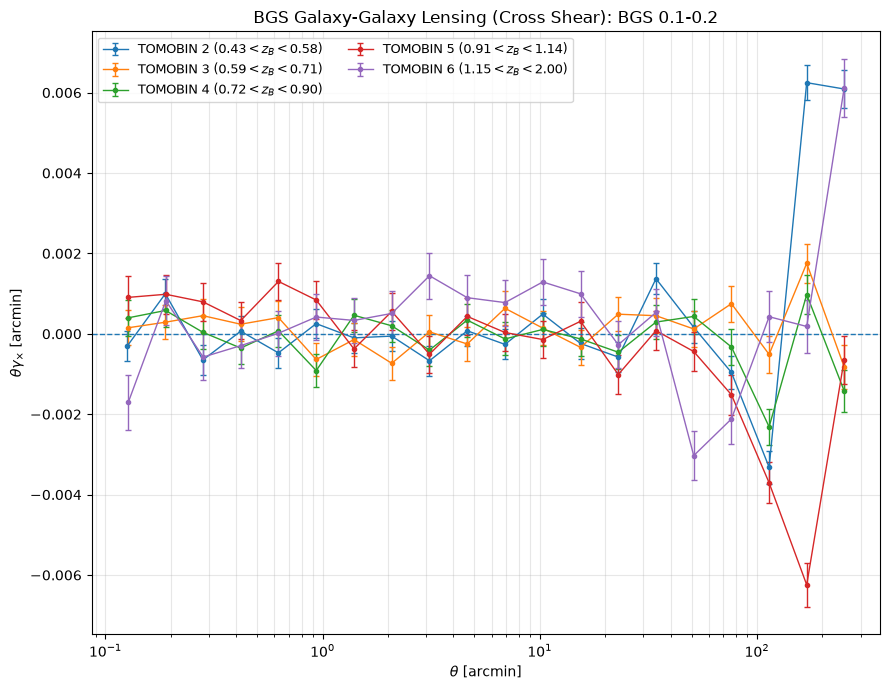

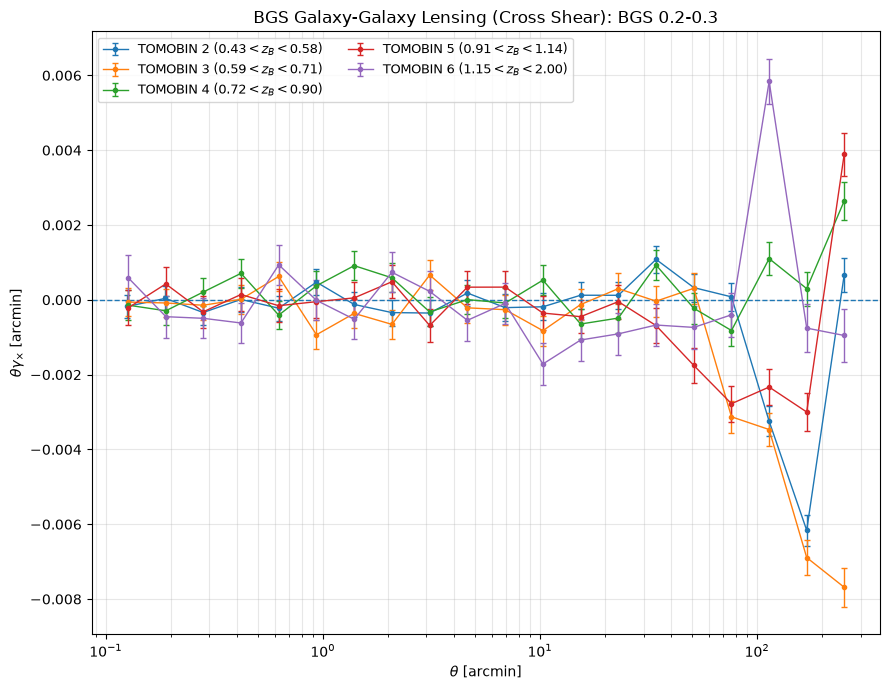

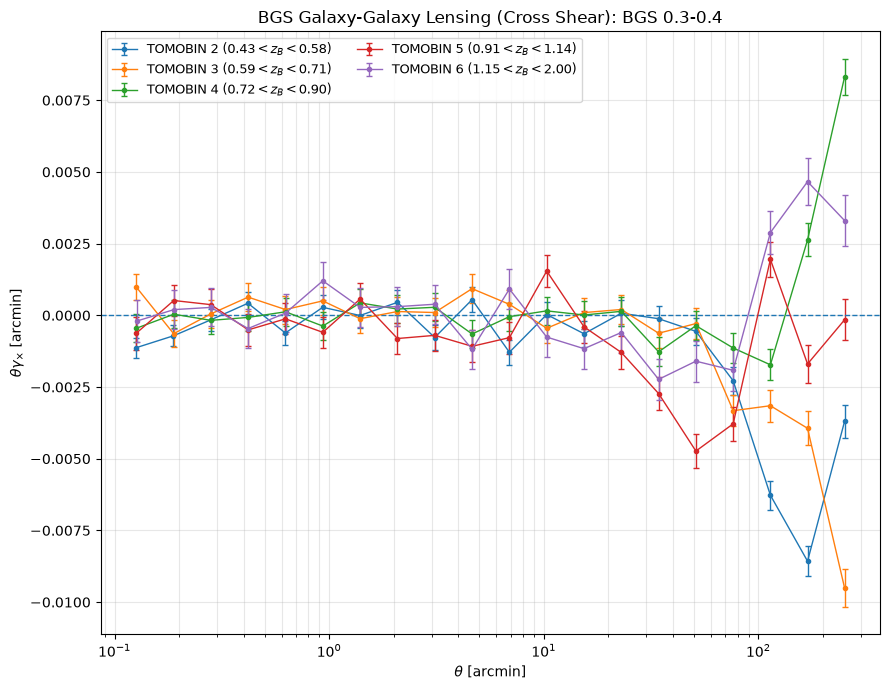

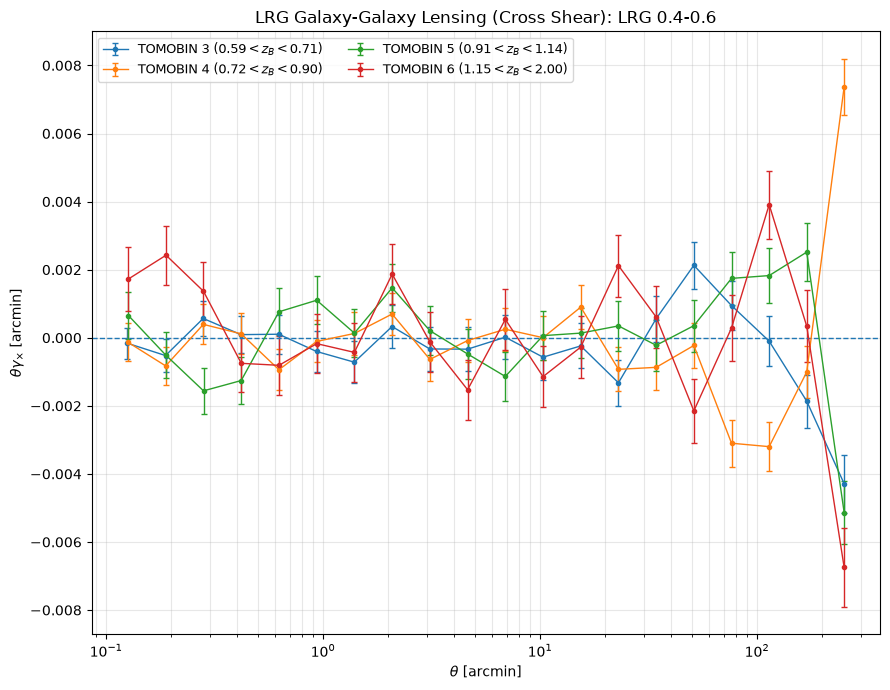

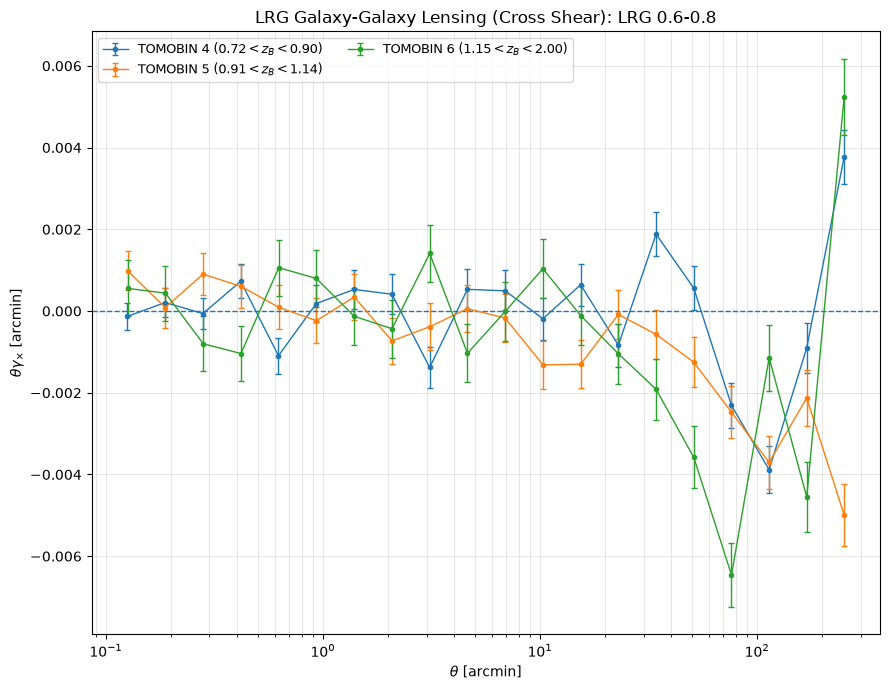

In [31]:
# ============================================================
# Plot: Kreuzschermodus gamma_x (BGS und LRG)
#
#     NUR erlaubte Source-TOMOBINs
#     y = theta * gamma_x
# ============================================================

for lens_name, lens_cats, allowed_combinations in (
    ("BGS", bgs_lens_cats, allowed_bgs_combinations),
    ("LRG", lrg_lens_cats, allowed_lrg_combinations),
):
    for lens_tomo_name in lens_cats:
        plt.figure(figsize=(9, 7))

        for source_bin in allowed_combinations[lens_tomo_name]:
            r, gammat, gammax, sigma, ng = ggl_results[
                (lens_tomo_name, source_bin)
            ]

            theta_gamma_x = r * gammax
            theta_gamma_x_error = r * sigma

            plt.errorbar(
                r,
                theta_gamma_x,
                yerr=theta_gamma_x_error,
                marker="o",
                markersize=3,
                linestyle="-",
                linewidth=1,
                capsize=2,
                label=source_bin_labels[source_bin],
            )

        plt.axhline(0, linestyle="--", linewidth=1)
        plt.xscale("log")
        plt.xlabel(r"$\theta$ [arcmin]")
        plt.ylabel(r"$\theta\gamma_{\times}$ [arcmin]")
        plt.title(
            f"{lens_name} Galaxy-Galaxy Lensing "
            f"(Cross Shear): {lens_tomo_name}"
        )
        plt.legend(fontsize=9, ncol=2)
        plt.grid(True, which="both", linestyle="-", alpha=0.3)
        plt.tight_layout()
        plt.show()


# Read in DESI Randoms for random substraction correction


Randoms are subtracted to remove spurious lensing signals caused by survey geometry, masking, and other additive systematics. Since random points have the same sky footprint as the lenses but no true physical correlation with the sources, the lens–random signal estimates the non-astrophysical background that should not be attributed to galaxy–galaxy lensing.

In [32]:
# =========================
# BGS ANY RANDOM
# =========================

with fits.open('/DATA02/rhoffmann/DESI/BGS ANY/BGS_ANY_RANDOM.fits') as hdul:
    bgs_rand_data = hdul[1].data

    bgs_rand_dict = {}

    for name in bgs_rand_data.names:
        column = bgs_rand_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        bgs_rand_dict[name] = np.array(column)

    bgs_any_random_df = pd.DataFrame(bgs_rand_dict)

print("BGS ANY RANDOM:", bgs_any_random_df.shape)


# =========================
# LRG RANDOM
# =========================

with fits.open('/DATA02/rhoffmann/DESI/LRG/LRG_RANDOM.fits') as hdul:
    lrg_rand_data = hdul[1].data

    lrg_rand_dict = {}

    for name in lrg_rand_data.names:
        column = lrg_rand_data[name]

        # Big-Endian -> native Byte-Reihenfolge
        if column.dtype.byteorder == '>':
            column = column.byteswap().view(
                column.dtype.newbyteorder('=')
            )

        # Native NumPy-Kopie
        lrg_rand_dict[name] = np.array(column)

    lrg_random_df = pd.DataFrame(lrg_rand_dict)

print("LRG RANDOM:", lrg_random_df.shape)

BGS ANY RANDOM: (48507159, 19)
LRG RANDOM: (47869224, 14)


In [33]:
print("\nBig-Endian-Spalten in BGS RANDOM:")
for column in bgs_any_random_df.columns:
    dtype = bgs_any_random_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)

print("\nBig-Endian-Spalten in LRG RANDOM:")
for column in lrg_random_df.columns:
    dtype = lrg_random_df[column].to_numpy().dtype
    if dtype.byteorder == '>':
        print(column, dtype)


Big-Endian-Spalten in BGS RANDOM:

Big-Endian-Spalten in LRG RANDOM:


# Filter Randoms with Footprint and check Random Data

In [34]:
bgs_any_random_footprint_df = filter_catalog_by_footprint(
    bgs_any_random_df,
    ra_column="desi_dr1_lss_v1_5_bgs_any_ran.ra",
    dec_column="desi_dr1_lss_v1_5_bgs_any_ran.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("BGS RANDOM vorher:", len(bgs_any_random_df))
print("BGS RANDOM nach Footprint:", len(bgs_any_random_footprint_df))

lrg_random_footprint_df = filter_catalog_by_footprint(
    lrg_random_df,
    ra_column="desi_dr1_lss_v1_5_lrg_ran.ra",
    dec_column="desi_dr1_lss_v1_5_lrg_ran.dec",
    footprint_mask=footprint_mask_saved,
    full_bin_size=full_bin_size,
    full_dec_min=full_dec_min,
)

print("LRG RANDOM vorher:", len(lrg_random_df))
print("LRG RANDOM nach Footprint:", len(lrg_random_footprint_df))

BGS RANDOM vorher: 48507159
BGS RANDOM nach Footprint: 26510334
LRG RANDOM vorher: 47869224
LRG RANDOM nach Footprint: 26023648


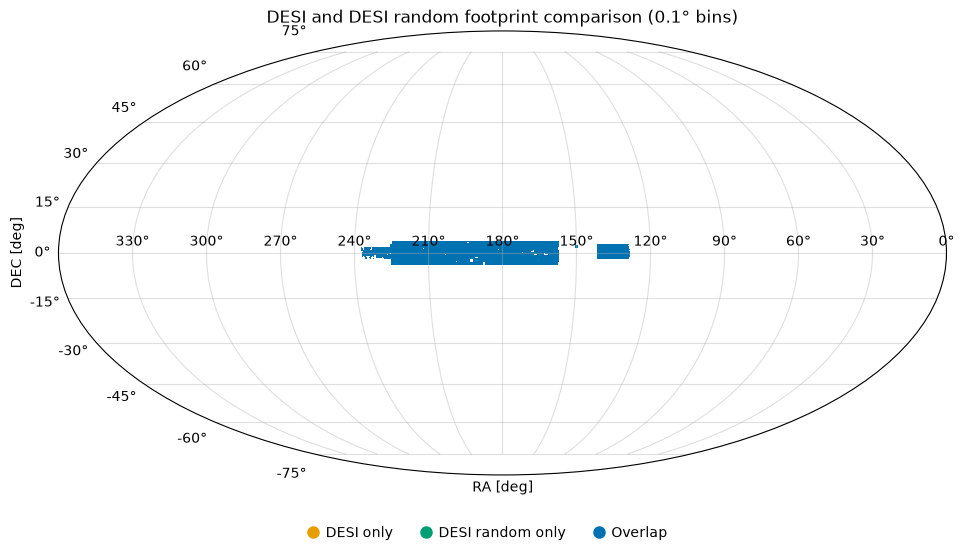

DESI fully covered by randoms: No
Overlapping bins: 64,529
DESI-only bins: 2
DESI-random-only bins: 91


In [35]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

random_counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for catalog in (bgs_any_random_footprint_df, lrg_random_footprint_df):
    ra_column = next(column for column in catalog.columns if column.lower().endswith('.ra'))
    dec_column = next(column for column in catalog.columns if column.lower().endswith('.dec'))
    ra_longitude = -((catalog[ra_column].to_numpy() % 360) - 180)
    random_counts += np.histogram2d(
        ra_longitude,
        catalog[dec_column].to_numpy(),
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

desi_occupied = desi_counts > 0
random_occupied = random_counts > 0
shared = desi_occupied & random_occupied
desi_only = desi_occupied & ~random_occupied
random_only = random_occupied & ~desi_occupied

comparison = np.zeros_like(desi_counts, dtype=np.uint8)
comparison[desi_only] = 1
comparison[random_only] = 2
comparison[shared] = 3

comparison_cmap = ListedColormap(['#e69f00', '#009e73', '#0072b2'])
comparison_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], comparison_cmap.N)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_equal(comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('DESI and DESI random footprint comparison (0.1° bins)')

legend_items = [
    Line2D([], [], marker='o', linestyle='None', color='#e69f00', markersize=8,
           label='DESI only'),
    Line2D([], [], marker='o', linestyle='None', color='#009e73', markersize=8,
           label='DESI random only'),
    Line2D([], [], marker='o', linestyle='None', color='#0072b2', markersize=8,
           label='Overlap'),
]
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.14)
plt.show()

print(f'DESI fully covered by randoms: {"Yes" if not np.any(desi_only) else "No"}')
print(f'Overlapping bins: {np.count_nonzero(shared):,}')
print(f'DESI-only bins: {np.count_nonzero(desi_only):,}')
print(f'DESI-random-only bins: {np.count_nonzero(random_only):,}')

In [36]:
# ============================================================
# DESI BGS random tomographic bins
# ============================================================

BGS_RANDOM_Z_COLUMN = "desi_dr1_lss_v1_5_bgs_any_ran.z"

bgs_random_tomo_bins = {}

for tomo_name, (z_min, z_max) in bgs_z_bins.items():

    mask = (
        np.isfinite(bgs_any_random_footprint_df[BGS_RANDOM_Z_COLUMN])
        & (bgs_any_random_footprint_df[BGS_RANDOM_Z_COLUMN] >= z_min)
        & (bgs_any_random_footprint_df[BGS_RANDOM_Z_COLUMN] < z_max)
    )

    bgs_random_tomo_bins[tomo_name] = (
        bgs_any_random_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name} random: "
        f"{len(bgs_random_tomo_bins[tomo_name])} randoms"
    )


# ============================================================
# DESI LRG random tomographic bins
# ============================================================

LRG_RANDOM_Z_COLUMN = "desi_dr1_lss_v1_5_lrg_ran.z"

lrg_random_tomo_bins = {}

for tomo_name, (z_min, z_max) in lrg_z_bins.items():

    mask = (
        np.isfinite(lrg_random_footprint_df[LRG_RANDOM_Z_COLUMN])
        & (lrg_random_footprint_df[LRG_RANDOM_Z_COLUMN] >= z_min)
        & (lrg_random_footprint_df[LRG_RANDOM_Z_COLUMN] < z_max)
    )

    lrg_random_tomo_bins[tomo_name] = (
        lrg_random_footprint_df.loc[mask].copy()
    )

    print(
        f"{tomo_name} random: "
        f"{len(lrg_random_tomo_bins[tomo_name])} randoms"
    )


print("\nBGS random tomographic bins:")
for name, df in bgs_random_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[BGS_RANDOM_Z_COLUMN].median():.3f}, "
        f"mean z = {df[BGS_RANDOM_Z_COLUMN].mean():.3f}"
    )


print("\nLRG random tomographic bins:")
for name, df in lrg_random_tomo_bins.items():

    print(
        f"{name:15s} "
        f"N = {len(df):8d}, "
        f"median z = {df[LRG_RANDOM_Z_COLUMN].median():.3f}, "
        f"mean z = {df[LRG_RANDOM_Z_COLUMN].mean():.3f}"
    )

BGS 0.1-0.2 random: 7663119 randoms
BGS 0.2-0.3 random: 8440019 randoms
BGS 0.3-0.4 random: 5282512 randoms
LRG 0.4-0.6 random: 6183398 randoms
LRG 0.6-0.8 random: 9369701 randoms

BGS random tomographic bins:
BGS 0.1-0.2     N =  7663119, median z = 0.155, mean z = 0.154
BGS 0.2-0.3     N =  8440019, median z = 0.247, mean z = 0.248
BGS 0.3-0.4     N =  5282512, median z = 0.342, mean z = 0.345

LRG random tomographic bins:
LRG 0.4-0.6     N =  6183398, median z = 0.514, mean z = 0.509
LRG 0.6-0.8     N =  9369701, median z = 0.708, mean z = 0.706


# Compare Tomobin Distribution of Randoms and real Data

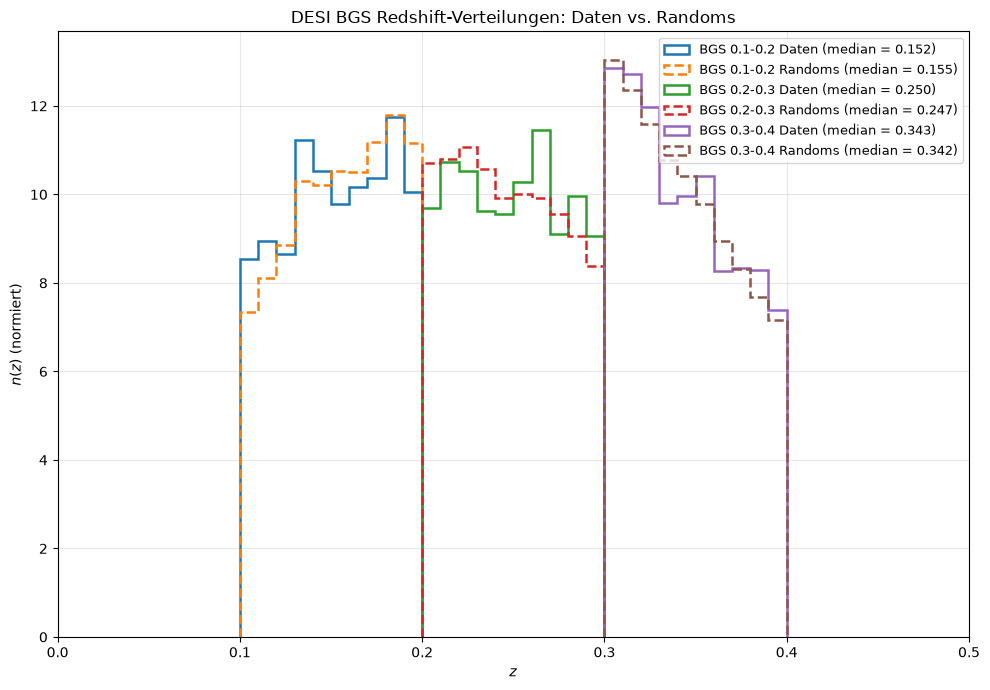

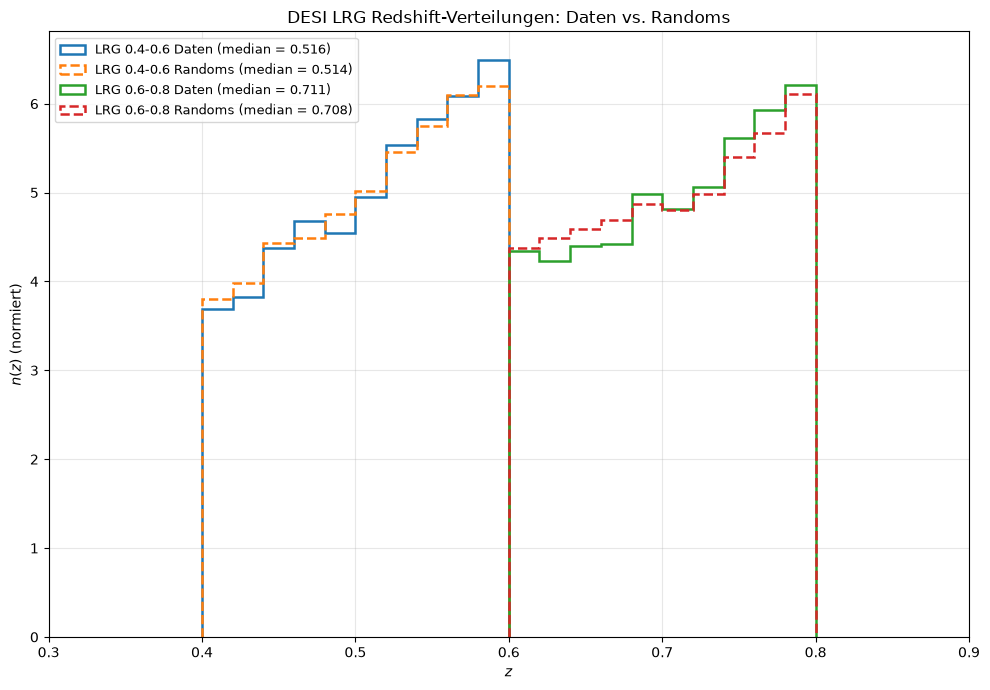

In [37]:
# ============================================================
# DESI BGS + LRG Redshift-Verteilungen: Daten vs. Randoms
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


def plot_data_vs_random_nz(
    data_bins,
    random_bins,
    data_z_column,
    random_z_column,
    z_bins,
    title,
    xlim,
):
    plt.figure(figsize=(10, 7))

    for color_index, tomo_name in enumerate(data_bins):

        z_min, z_max = z_bins[tomo_name]
        edges = np.linspace(z_min, z_max, 11)

        z_data = data_bins[tomo_name][data_z_column].to_numpy(
            dtype=np.float64
        )
        z_data = z_data[np.isfinite(z_data)]

        z_random = random_bins[tomo_name][random_z_column].to_numpy(
            dtype=np.float64
        )
        z_random = z_random[np.isfinite(z_random)]

        # Randoms sind viel zahlreicher -> normierte Verteilungen vergleichen
        if len(z_data) > 0:
            plt.hist(
                z_data,
                bins=edges,
                density=True,
                histtype="step",
                linewidth=1.8,
                linestyle="-",
                label=(
                    f"{tomo_name} Daten "
                    f"(median = {np.median(z_data):.3f})"
                ),
            )

        if len(z_random) > 0:
            plt.hist(
                z_random,
                bins=edges,
                density=True,
                histtype="step",
                linewidth=1.8,
                linestyle="--",
                label=(
                    f"{tomo_name} Randoms "
                    f"(median = {np.median(z_random):.3f})"
                ),
            )

    plt.xlabel(r"$z$")
    plt.ylabel(r"$n(z)$ (normiert)")
    plt.title(title)
    plt.xlim(*xlim)
    plt.grid(True, linestyle="-", alpha=0.3)
    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


plot_data_vs_random_nz(
    bgs_tomo_bins,
    bgs_random_tomo_bins,
    BGS_Z_COLUMN,
    BGS_RANDOM_Z_COLUMN,
    bgs_z_bins,
    "DESI BGS Redshift-Verteilungen: Daten vs. Randoms",
    (0.0, 0.5),
)

plot_data_vs_random_nz(
    lrg_tomo_bins,
    lrg_random_tomo_bins,
    LRG_Z_COLUMN,
    LRG_RANDOM_Z_COLUMN,
    lrg_z_bins,
    "DESI LRG Redshift-Verteilungen: Daten vs. Randoms",
    (0.3, 0.9),
)

# Shearsignal with random substration and multiplicative shear bias correction

Erstelle KiDS Source-Kataloge
KiDS TOMOBIN 1: 3,683,163 Quellen (Z_B ~ 0.11-0.42)
KiDS TOMOBIN 2: 3,779,080 Quellen (Z_B ~ 0.43-0.58)
KiDS TOMOBIN 3: 3,449,734 Quellen (Z_B ~ 0.59-0.71)
KiDS TOMOBIN 4: 3,367,244 Quellen (Z_B ~ 0.72-0.90)
KiDS TOMOBIN 5: 3,105,132 Quellen (Z_B ~ 0.91-1.14)
KiDS TOMOBIN 6: 2,804,194 Quellen (Z_B ~ 1.15-2.00)


Erstelle DESI BGS Lens- und Random-Kataloge
BGS 0.1-0.2: 165,717 Lenses, 7,663,119 Randoms
BGS 0.2-0.3: 183,190 Lenses, 8,440,019 Randoms
BGS 0.3-0.4: 115,895 Lenses, 5,282,512 Randoms


Erstelle DESI LRG Lens- und Random-Kataloge
LRG 0.4-0.6: 67,741 Lenses, 6,183,398 Randoms
LRG 0.6-0.8: 104,687 Lenses, 9,369,701 Randoms


Median-Redshifts
KiDS TOMOBIN 1: median z = 0.3100
KiDS TOMOBIN 2: median z = 0.5100
KiDS TOMOBIN 3: median z = 0.6400
KiDS TOMOBIN 4: median z = 0.8100
KiDS TOMOBIN 5: median z = 1.0100
KiDS TOMOBIN 6: median z = 1.3400
BGS 0.1-0.2: median z = 0.1520
BGS 0.2-0.3: median z = 0.2498
BGS 0.3-0.4: median z = 0.3427
LRG 0.4-0.6: med

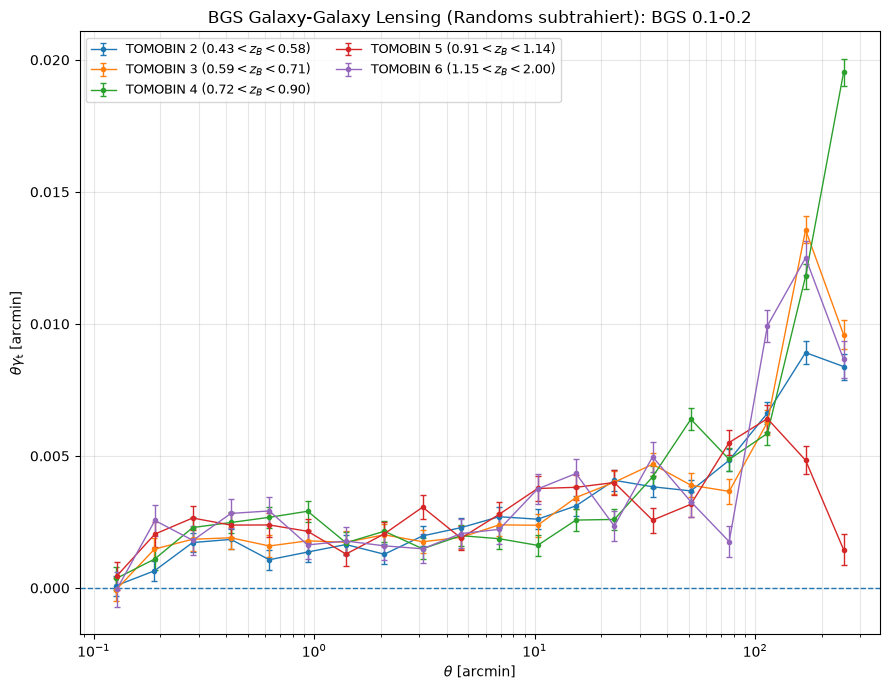

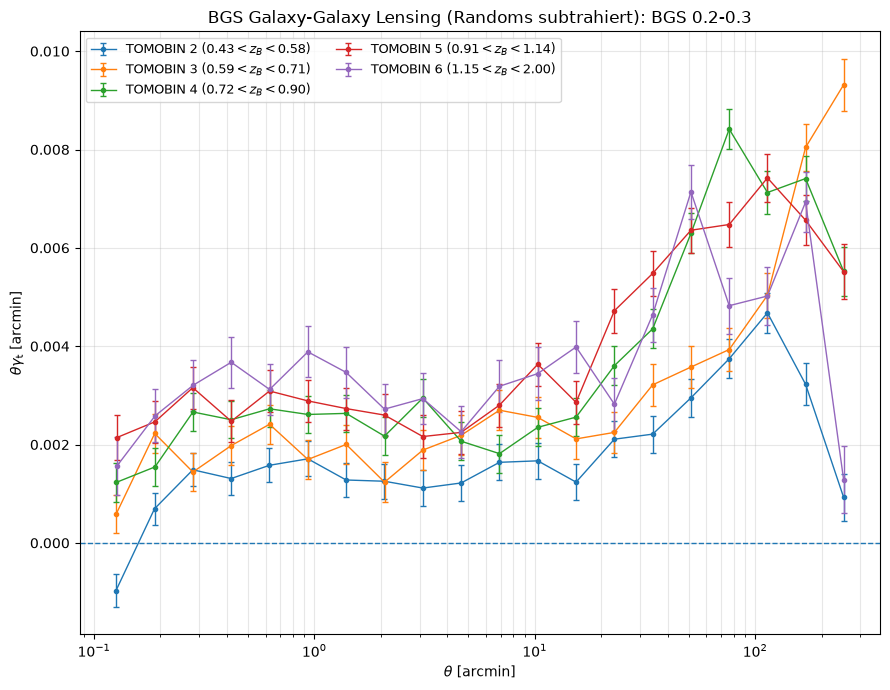

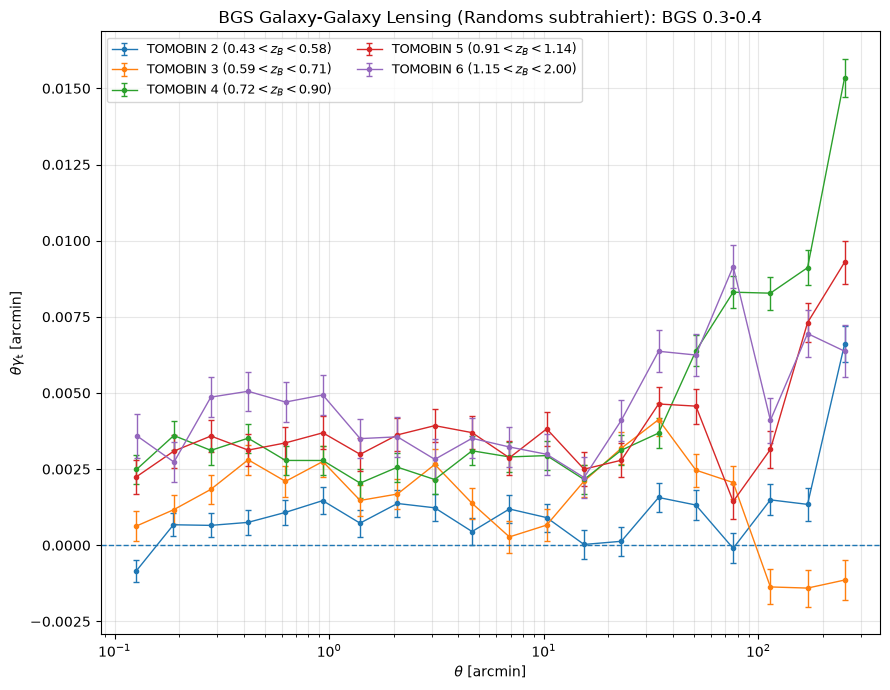

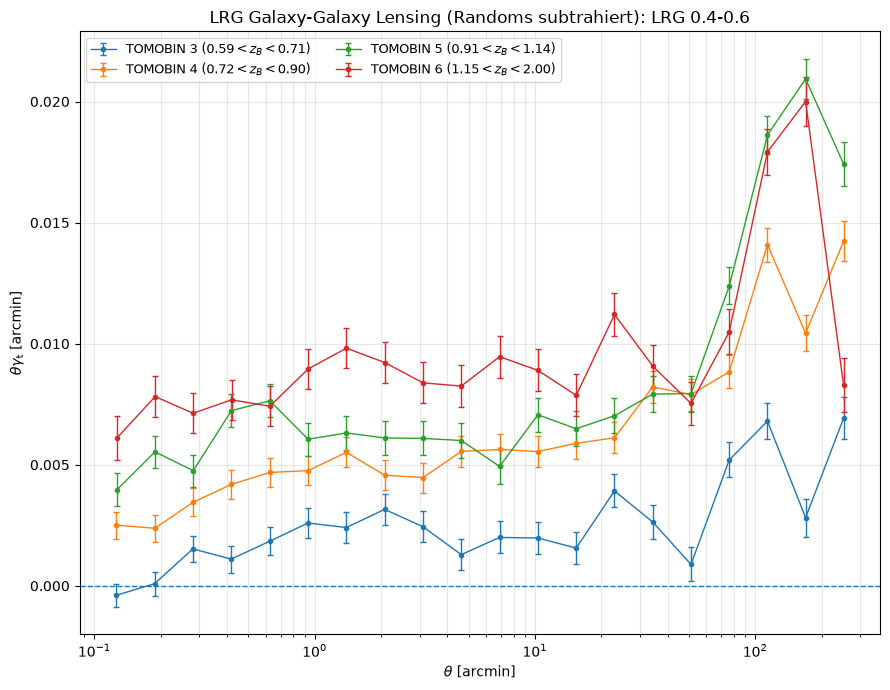

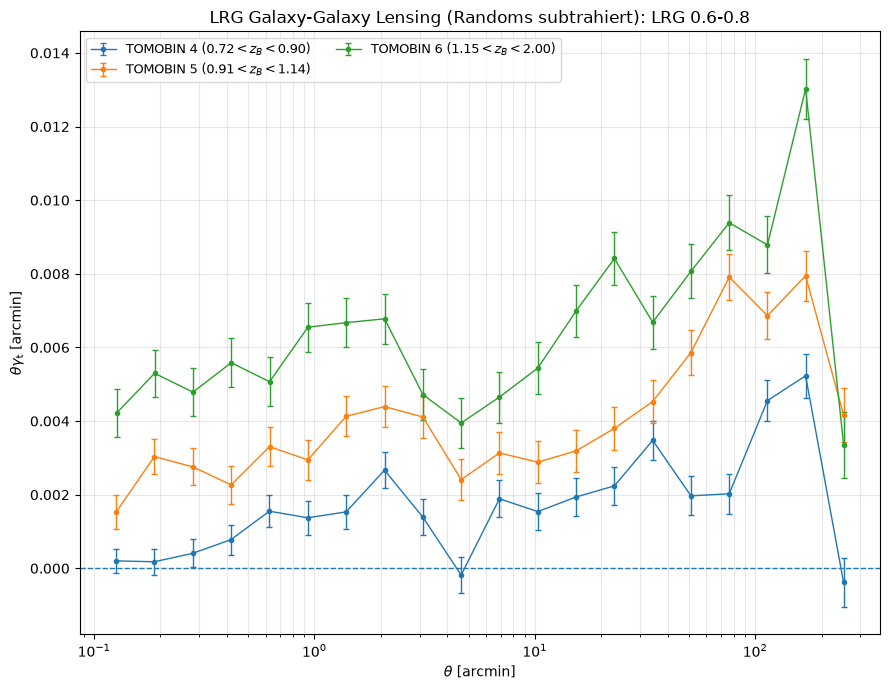

In [45]:
import numpy as np
import treecorr
import matplotlib.pyplot as plt


# ============================================================
# TreeCorr-Konfiguration
# ============================================================

config = {
    "nbins": 20,
    "min_sep": 0.1,
    "max_sep": 300.0,
    "sep_units": "arcmin",
}


# ============================================================
# Definition der Tomographie
# ============================================================

kids_tomo_bins = {
    1: (0.11, 0.42),
    2: (0.43, 0.58),
    3: (0.59, 0.71),
    4: (0.72, 0.90),
    5: (0.91, 1.14),
    6: (1.15, 2.00),
}

bgs_z_column = "desi_dr1_lss_v1_5_bgs_any_dat.z"
bgs_random_z_column = "desi_dr1_lss_v1_5_bgs_any_ran.z"

bgs_z_bins = {
    "BGS 0.1-0.2": (0.1, 0.2),
    "BGS 0.2-0.3": (0.2, 0.3),
    "BGS 0.3-0.4": (0.3, 0.4),
}

lrg_z_column = "desi_dr1_lss_v1_5_lrg_dat.z"
lrg_random_z_column = "desi_dr1_lss_v1_5_lrg_ran.z"

lrg_z_bins = {
    "LRG 0.4-0.6": (0.4, 0.6),
    "LRG 0.6-0.8": (0.6, 0.8),
}

# Published KiDS-GOLD multiplicative shear biases, mapped by source TOMOBIN.
kids_m_gold = {
    1: -0.0229,
    2: -0.0160,
    3: -0.0113,
    4:  0.0199,
    5:  0.0295,
    6:  0.0445,
}

# Apply M_KiDS = 1 / (1 + m_gold) to each source-bin signal.
kids_m_calibration = {
    tomo_bin: 1.0 / (1.0 + m_gold)
    for tomo_bin, m_gold in kids_m_gold.items()
}


# ============================================================
# Filter-KRITERIUM
#
# Eine Source-TOMOBIN wird nur dann hinter einem Lens-TOMOBIN
# akzeptiert, wenn 100% ihrer Quellen mit gültigem z_source
# hinter dem medianen Lens-Redshift liegen.
# ============================================================

# ============================================================
# 1. KiDS Source-Kataloge für alle TOMOBINs
# ============================================================

print("=" * 75)
print("Erstelle KiDS Source-Kataloge")
print("=" * 75)

kids_source_cats = {}
kids_tomo_dfs = {}

for tomo_bin, (z_min, z_max) in kids_tomo_bins.items():

    tomo_df = kids_df_footprint.loc[
        kids_df_footprint["TOMOBIN"] == tomo_bin
    ].copy()

    kids_tomo_dfs[tomo_bin] = tomo_df

    kids_source_cats[tomo_bin] = treecorr.Catalog(
        ra=tomo_df["RAJ2000"].to_numpy(dtype=np.float64),
        dec=tomo_df["DECJ2000"].to_numpy(dtype=np.float64),
        ra_units="deg",
        dec_units="deg",
        g1=tomo_df["e1"].to_numpy(dtype=np.float64),
        g2=tomo_df["e2"].to_numpy(dtype=np.float64),
        w=tomo_df["weight"].to_numpy(dtype=np.float64),
    )

    print(
        f"KiDS TOMOBIN {tomo_bin}: "
        f"{len(tomo_df):,} Quellen "
        f"(Z_B ~ {z_min:.2f}-{z_max:.2f})"
    )


# ============================================================
# 2. DESI Lens- und Random-Kataloge (BGS und LRG)
#
#    Randoms werden in dieselben z-Bins wie die Lenses sortiert.
# ============================================================

def build_tomo_catalogs(
    df,
    z_column,
    ra_column,
    dec_column,
    z_bins,
):
    tomo_dfs = {}
    tomo_cats = {}

    for tomo_name, (z_min, z_max) in z_bins.items():

        z = df[z_column]

        mask = (
            np.isfinite(z)
            & (z >= z_min)
            & (z < z_max)
        )

        tomo_df = df.loc[mask].copy()

        tomo_dfs[tomo_name] = tomo_df

        tomo_cats[tomo_name] = treecorr.Catalog(
            ra=tomo_df[ra_column].to_numpy(dtype=np.float64),
            dec=tomo_df[dec_column].to_numpy(dtype=np.float64),
            ra_units="deg",
            dec_units="deg",
        )

    return tomo_dfs, tomo_cats


print("\n")
print("=" * 75)
print("Erstelle DESI BGS Lens- und Random-Kataloge")
print("=" * 75)

bgs_tomo_dfs, bgs_lens_cats = build_tomo_catalogs(
    bgs_any_footprint_df,
    bgs_z_column,
    "desi_dr1_lss_v1_5_bgs_any_dat.ra",
    "desi_dr1_lss_v1_5_bgs_any_dat.dec",
    bgs_z_bins,
)

bgs_random_tomo_dfs, bgs_random_cats = build_tomo_catalogs(
    bgs_any_random_footprint_df,
    bgs_random_z_column,
    "desi_dr1_lss_v1_5_bgs_any_ran.ra",
    "desi_dr1_lss_v1_5_bgs_any_ran.dec",
    bgs_z_bins,
)

for tomo_name in bgs_z_bins:
    print(
        f"{tomo_name}: "
        f"{len(bgs_tomo_dfs[tomo_name]):,} Lenses, "
        f"{len(bgs_random_tomo_dfs[tomo_name]):,} Randoms"
    )


print("\n")
print("=" * 75)
print("Erstelle DESI LRG Lens- und Random-Kataloge")
print("=" * 75)

lrg_tomo_dfs, lrg_lens_cats = build_tomo_catalogs(
    lrg_footprint_df,
    lrg_z_column,
    "desi_dr1_lss_v1_5_lrg_dat.ra",
    "desi_dr1_lss_v1_5_lrg_dat.dec",
    lrg_z_bins,
)

lrg_random_tomo_dfs, lrg_random_cats = build_tomo_catalogs(
    lrg_random_footprint_df,
    lrg_random_z_column,
    "desi_dr1_lss_v1_5_lrg_ran.ra",
    "desi_dr1_lss_v1_5_lrg_ran.dec",
    lrg_z_bins,
)

for tomo_name in lrg_z_bins:
    print(
        f"{tomo_name}: "
        f"{len(lrg_tomo_dfs[tomo_name]):,} Lenses, "
        f"{len(lrg_random_tomo_dfs[tomo_name]):,} Randoms"
    )


# ============================================================
# 3. Median-Redshifts (Quellen und Lenses)
# ============================================================

def median_redshift(df, z_column):
    z = df[z_column].to_numpy(dtype=np.float64)
    z = z[np.isfinite(z)]
    return np.median(z) if len(z) > 0 else np.nan


source_z_column = "Z_B"

print("\n")
print("=" * 75)
print("Median-Redshifts")
print("=" * 75)

kids_source_z_median = {}
for source_bin, df in kids_tomo_dfs.items():
    kids_source_z_median[source_bin] = median_redshift(df, source_z_column)
    print(
        f"KiDS TOMOBIN {source_bin}: "
        f"median z = {kids_source_z_median[source_bin]:.4f}"
    )

bgs_lens_z_median = {}
for name, df in bgs_tomo_dfs.items():
    bgs_lens_z_median[name] = median_redshift(df, bgs_z_column)
    print(f"{name}: median z = {bgs_lens_z_median[name]:.4f}")

lrg_lens_z_median = {}
for name, df in lrg_tomo_dfs.items():
    lrg_lens_z_median[name] = median_redshift(df, lrg_z_column)
    print(f"{name}: median z = {lrg_lens_z_median[name]:.4f}")


# ============================================================
# 4. Anteil der KiDS-Quellen hinter dem Lens (Information)
# ============================================================

def source_fraction_behind(
    source_df,
    z_source_column,
    z_lens,
):

    z_source = source_df[z_source_column].to_numpy(dtype=np.float64)
    z_source = z_source[np.isfinite(z_source)]

    if len(z_source) == 0:
        return np.nan

    return np.mean(z_source > z_lens)


# ============================================================
# 5. Source/Lens-Filter (100% der Quellen hinter dem Lens)
# ============================================================

def filter_source_bins(label, lens_z_median):

    print("\n")
    print("=" * 75)
    print(f"{label} Source/Lens-TOMOBIN Filter")
    print("=" * 75)

    allowed_combinations = {}
    behind_fraction = {}

    for lens_name, z_lens_median in lens_z_median.items():

        allowed_combinations[lens_name] = []
        behind_fraction[lens_name] = {}

        print("\n")
        print(lens_name)
        print(f"  Lens median z = {z_lens_median:.4f}")
        print(
            f"  Filter-Kriterium: 100% der gültigen Quellen hinter Lens "
            f"(z_source > {z_lens_median:.4f})"
        )

        for source_bin in sorted(kids_tomo_dfs):

            z_source_median = kids_source_z_median[source_bin]

            fraction = source_fraction_behind(
                kids_tomo_dfs[source_bin],
                source_z_column,
                z_lens_median,
            )

            behind_fraction[lens_name][source_bin] = fraction

            allowed = (
                np.isfinite(z_source_median)
                and np.isfinite(z_lens_median)
                and np.isfinite(fraction)
                and fraction == 1.0
            )

            if allowed:
                status = "ERLAUBT"
                allowed_combinations[lens_name].append(source_bin)
            else:
                status = "GEFILTERT"

            print(
                f"    KiDS TOMOBIN {source_bin}: "
                f"median z_s = {z_source_median:.4f}, "
                f"{fraction * 100:.1f}% hinter Lens "
                f"--> {status}"
            )

    return allowed_combinations, behind_fraction


allowed_bgs_combinations, bgs_source_behind_fraction = filter_source_bins(
    "BGS", bgs_lens_z_median
)

allowed_lrg_combinations, lrg_source_behind_fraction = filter_source_bins(
    "LRG", lrg_lens_z_median
)


print("\n")
print("=" * 75)
print("ERLAUBTE GGL-KOMBINATIONEN")
print("=" * 75)

print("\nBGS:")
for name, source_bins in allowed_bgs_combinations.items():
    print(f"  {name}: KiDS TOMOBINs {source_bins}")

print("\nLRG:")
for name, source_bins in allowed_lrg_combinations.items():
    print(f"  {name}: KiDS TOMOBINs {source_bins}")


# ============================================================
# 6. GGL-Profil mit Random-Subtraktion
#
#    Lens-Signal und Random-Signal werden mit identischer
#    Konfiguration gegen dieselben Quellen berechnet. TreeCorr
#    normiert jedes Signal auf seine eigene Gewichtssumme
#    (pro Radiusbin).
#
#        gamma_t = gamma_t,lens - gamma_t,rand
#
#    Multiplikative KiDS-GOLD-Korrektur:
#        gamma_t,cal = M_KiDS * (gamma_t,lens - gamma_t,rand)
#        M_KiDS = 1 / (1 + m_gold) pro Source-TOMOBIN.
#    Die Fehler werden mit demselben M_KiDS skaliert; die
#    Unsicherheit von m_gold selbst ist hier nicht enthalten.
# ============================================================

def calculate_ggl_profile(
    lens_cat,
    random_cat,
    source_cat,
    config,
    m_calibration,
):

    """
    Berechnet ein Galaxy-Galaxy-Lensing-Profil mit TreeCorr
    und subtrahiert das Signal um Random-Punkte.
    """

    ng = treecorr.NGCorrelation(config)
    ng.process(lens_cat, source_cat)

    rg = treecorr.NGCorrelation(config)
    rg.process(random_cat, source_cat)

    r = ng.meanr

    gammat = m_calibration * (ng.xi - rg.xi)

    gammax = m_calibration * (ng.xi_im - rg.xi_im)

    sigma = m_calibration * np.sqrt(ng.varxi + rg.varxi)

    return (
        r,
        gammat,
        gammax,
        sigma,
        ng,
        rg,
    )


ggl_results = {}


def run_ggl(label, lens_cats, random_cats, allowed_combinations):

    print("\n")
    print("=" * 75)
    print(f"Berechne {label} × KiDS tomographisches GGL (Randoms subtrahiert)")
    print("=" * 75)

    for lens_name, lens_cat in lens_cats.items():

        print(f"\n{lens_name}")

        for source_bin in allowed_combinations[lens_name]:

            m_gold = kids_m_gold[source_bin]
            m_calibration = kids_m_calibration[source_bin]
            print(
                f"    {lens_name} × KiDS TOMOBIN {source_bin}: "
                f"m_gold={m_gold:+.4f}, M_KiDS={m_calibration:.5f}"
            )

            ggl_results[(lens_name, source_bin)] = calculate_ggl_profile(
                lens_cat,
                random_cats[lens_name],
                kids_source_cats[source_bin],
                config,
                m_calibration,
            )


run_ggl("BGS", bgs_lens_cats, bgs_random_cats, allowed_bgs_combinations)
run_ggl("LRG", lrg_lens_cats, lrg_random_cats, allowed_lrg_combinations)


# ============================================================
# 8. Plots: theta * gamma_t (Randoms subtrahiert)
#
#    NUR erlaubte Source-TOMOBINs
# ============================================================

source_bin_labels = {
    1: r"TOMOBIN 1 ($0.11 < z_B < 0.42$)",
    2: r"TOMOBIN 2 ($0.43 < z_B < 0.58$)",
    3: r"TOMOBIN 3 ($0.59 < z_B < 0.71$)",
    4: r"TOMOBIN 4 ($0.72 < z_B < 0.90$)",
    5: r"TOMOBIN 5 ($0.91 < z_B < 1.14$)",
    6: r"TOMOBIN 6 ($1.15 < z_B < 2.00$)",
}


def plot_ggl(label, lens_names, allowed_combinations):

    for lens_name in lens_names:

        plt.figure(figsize=(9, 7))

        for source_bin in allowed_combinations[lens_name]:

            r, gammat, gammax, sigma, ng, rg = ggl_results[
                (lens_name, source_bin)
            ]

            plt.errorbar(
                r,
                r * gammat,
                yerr=r * sigma,
                marker="o",
                markersize=3,
                linestyle="-",
                linewidth=1,
                capsize=2,
                label=source_bin_labels[source_bin],
            )

        plt.axhline(0, linestyle="--", linewidth=1)
        plt.xscale("log")
        plt.xlabel(r"$\theta$ [arcmin]")
        plt.ylabel(r"$\theta\gamma_{\rm t}$ [arcmin]")
        plt.title(
            f"{label} Galaxy-Galaxy Lensing (Randoms subtrahiert): "
            f"{lens_name}"
        )
        plt.legend(fontsize=9, ncol=2)
        plt.grid(True, which="both", linestyle="-", alpha=0.3)
        plt.tight_layout()
        plt.show()


plot_ggl("BGS", bgs_lens_cats, allowed_bgs_combinations)
plot_ggl("LRG", lrg_lens_cats, allowed_lrg_combinations)

# Check if Shear Signal of Randoms is compatiable with 0

Null-Test: Random-Signal verträglich mit 0?
Lens           Source   chi2_t      p_t   chi2_x      p_x  dof  Ergebnis
BGS 0.1-0.2         2  6228.02    0.000  6600.25    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.1-0.2         3  3851.01    0.000  1768.13    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.1-0.2         4  9020.06    0.000  4158.86    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.1-0.2         5  1112.17    0.000  1155.79    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.1-0.2         6  6441.85    0.000  1764.49    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.2-0.3         2  6691.71    0.000  7276.30    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.2-0.3         3  4435.11    0.000  1524.00    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.2-0.3         4 11796.53    0.000  4388.64    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.2-0.3         5  1409.80    0.000  1570.08    0.000   20  AUFFÄLLIG (Systematik?)
BGS 0.2-0.3         6  7399.38    0.000  1911.93    0.000   20  AUFFÄLLIG (Systematik?)
BGS

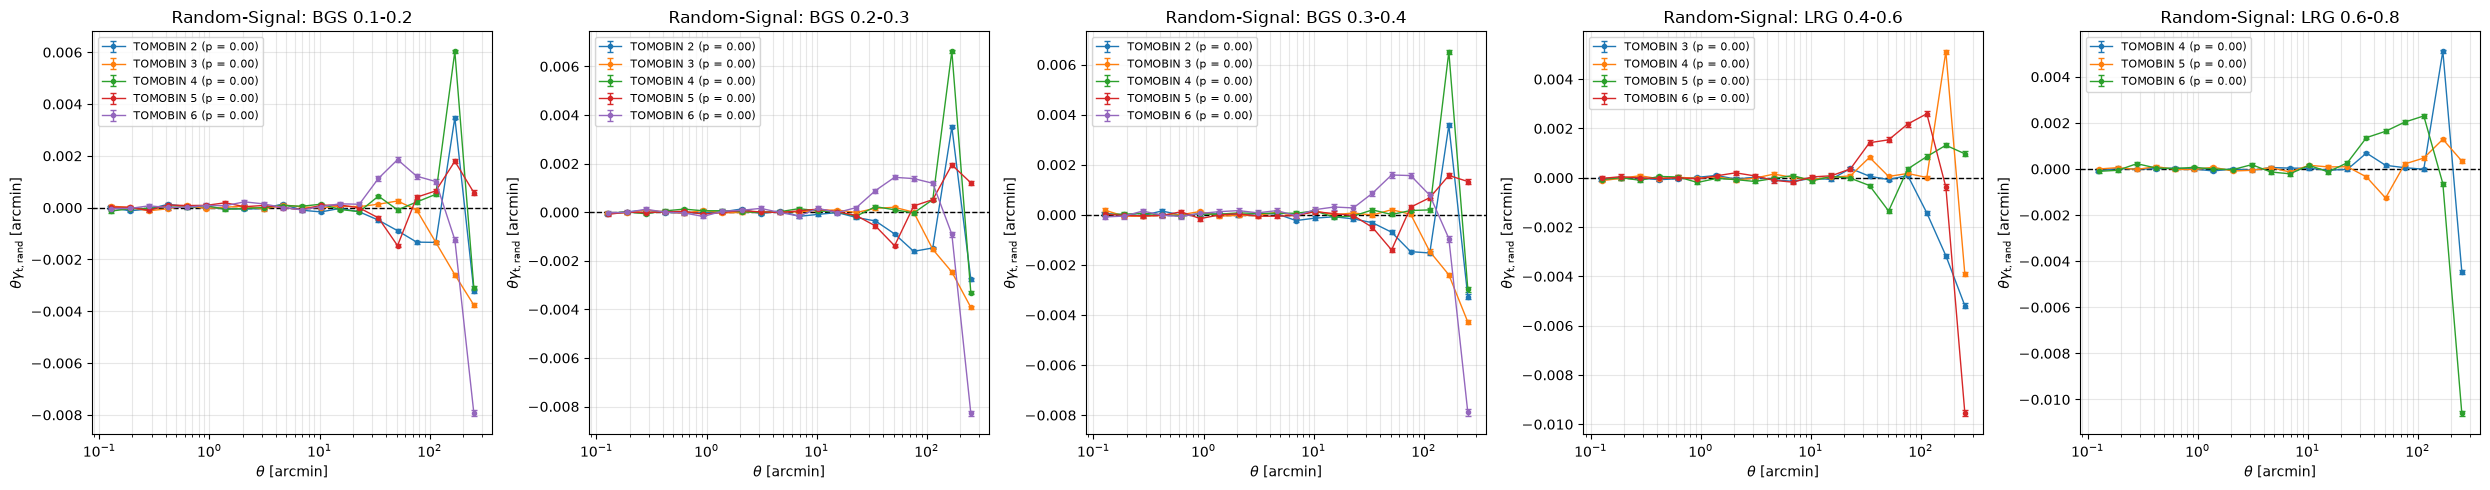

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# Null-Test: Random-Signal gamma_t,rand muss mit 0 verträglich sein
#
# Für jedes Lens/Source-Paar aus ggl_results wird das reine
# Random-Signal (rg) auf Verträglichkeit mit Null geprüft:
#
#     chi2 = sum( (gamma_t,rand / sigma)^2 ),  dof = Anzahl Radiusbins
#
# Es wird nur die Diagonale der Kovarianz verwendet (TreeCorr-
# Shape-Noise-Fehler), Korrelationen zwischen Radiusbins werden
# ignoriert. Ein p-Wert < 0.05 deutet auf Systematiken hin.
# ============================================================

null_test_results = {}

print("=" * 95)
print("Null-Test: Random-Signal verträglich mit 0?")
print("=" * 95)
print(
    f"{'Lens':14s} {'Source':>6s} "
    f"{'chi2_t':>8s} {'p_t':>8s} "
    f"{'chi2_x':>8s} {'p_x':>8s} "
    f"{'dof':>4s}  Ergebnis"
)

for (lens_name, source_bin), result in ggl_results.items():

    r, _, _, _, ng, rg = result

    xi_t = rg.xi
    xi_x = rg.xi_im
    sigma = np.sqrt(rg.varxi)

    valid = np.isfinite(xi_t) & np.isfinite(xi_x) & (sigma > 0)

    dof = int(np.count_nonzero(valid))

    chi2_t = np.sum((xi_t[valid] / sigma[valid]) ** 2)
    chi2_x = np.sum((xi_x[valid] / sigma[valid]) ** 2)

    p_t = stats.chi2.sf(chi2_t, dof)
    p_x = stats.chi2.sf(chi2_x, dof)

    # Gewichteter Mittelwert über alle Radiusbins
    weights = 1.0 / sigma[valid] ** 2
    mean_t = np.sum(weights * xi_t[valid]) / np.sum(weights)
    mean_t_err = 1.0 / np.sqrt(np.sum(weights))

    consistent = (p_t >= 0.05) and (p_x >= 0.05)

    null_test_results[(lens_name, source_bin)] = {
        "chi2_t": chi2_t,
        "p_t": p_t,
        "chi2_x": chi2_x,
        "p_x": p_x,
        "dof": dof,
        "mean_t": mean_t,
        "mean_t_err": mean_t_err,
        "consistent": consistent,
    }

    print(
        f"{lens_name:14s} {source_bin:6d} "
        f"{chi2_t:8.2f} {p_t:8.3f} "
        f"{chi2_x:8.2f} {p_x:8.3f} "
        f"{dof:4d}  "
        f"{'OK (mit 0 verträglich)' if consistent else 'AUFFÄLLIG (Systematik?)'}"
    )

n_ok = sum(v["consistent"] for v in null_test_results.values())
print(f"\n{n_ok} von {len(null_test_results)} Kombinationen mit 0 verträglich.")


# ============================================================
# Plot: theta * gamma_t,rand mit Fehlerbalken (erwartet: um 0)
# ============================================================

lens_names = list(dict.fromkeys(k[0] for k in ggl_results))

fig, axes = plt.subplots(
    1,
    len(lens_names),
    figsize=(5 * len(lens_names), 5),
    sharey=False,
    squeeze=False,
)

for ax, lens_name in zip(axes[0], lens_names):

    for (name, source_bin), result in ggl_results.items():

        if name != lens_name:
            continue

        r, _, _, _, ng, rg = result

        ax.errorbar(
            r,
            r * rg.xi,
            yerr=r * np.sqrt(rg.varxi),
            marker="o",
            markersize=3,
            linewidth=1,
            capsize=2,
            label=(
                f"TOMOBIN {source_bin} "
                f"(p = {null_test_results[(name, source_bin)]['p_t']:.2f})"
            ),
        )

    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\theta$ [arcmin]")
    ax.set_ylabel(r"$\theta\gamma_{\rm t,rand}$ [arcmin]")
    ax.set_title(f"Random-Signal: {lens_name}")
    ax.grid(True, which="both", linestyle="-", alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Kurz: Der Test schlägt überall extrem aus, aber das heißt nicht automatisch, dass dein Signal kaputt ist. Er sagt, dass das Random-Signal nicht mit 0 verträglich ist, wenn man nur die Shape-Noise-Fehler verwendet.

Die Zahlen

Erwartet wären χ² ≈ 20 bei 20 Freiheitsgraden. Du hast χ² von etwa 800 bis 14 000, also Abweichungen von grob 6σ bis 25σ pro Bin im Mittel. Alle 22 Kombinationen sind betroffen, und der p-Wert ist überall 0.
Auch die Kreuzkomponente γ_x ist stark auffällig. Das ist der wichtigste Hinweis. Ein echtes physikalisches Lensing-Signal um Randoms gäbe es nicht, und γ_x ist normalerweise der Null-Test schlechthin. Der Effekt kommt also fast sicher aus der Methode oder den Daten, nicht aus der Physik.
Wahrscheinliche Ursachen

Additiver Shear-Bias (c-Term): Wenn in KiDS e1 und e2 nicht um den additiven Bias korrigiert sind, ist die mittlere Ellipitizität ≠ 0. Dann liefert jede Lens-Verteilung, auch Randoms, ein Signal. Das passt gut zu auffälligem γ_t und γ_x zugleich.
Geometrie und Randeffekte: Die Randoms decken den Footprint nicht genau so ab wie die Quellen. Dann mittelt sich die Tangentialkomponente nicht zu 0.
Zu kleine Fehler: Mit sehr vielen Randoms wird der Shape-Noise-Fehler winzig. Die echte Unsicherheit, etwa Kosmische Varianz, PSF-Residuen oder Footprint, steckt nicht in varxi. Der Test ist daher sehr streng.

Mean-Shear pro Source-TOMOBIN (gewichtet)
TOMOBIN            N        <e1>        err    sig        <e2>        err    sig
      1    3,683,163    1.41e-05    1.5e-04    0.1   -1.10e-06    1.6e-04    0.0
      2    3,779,080    1.05e-05    1.6e-04    0.1    1.84e-05    1.6e-04    0.1
      3    3,449,734    5.14e-06    1.8e-04    0.0    4.84e-05    1.8e-04    0.3
      4    3,367,244    1.64e-05    1.7e-04    0.1    1.71e-05    1.7e-04    0.1
      5    3,105,132    1.23e-05    1.9e-04    0.1    7.82e-06    1.9e-04    0.0


      6    2,804,194    1.63e-05    2.4e-04    0.1    1.51e-05    2.4e-04    0.1

'sig' = |Mean| / Fehler. Werte >> 3 deuten auf additiven Bias hin.


Random- vs. Lens-Signal
Lens           Source  sum|rand|/sum|lens|  median Verh.  max Verh.  rand/err_lens (rms)
BGS 0.1-0.2         2                0.071         0.063       0.63                 2.61
BGS 0.1-0.2         3                0.050         0.027     263.11                 2.06
BGS 0.1-0.2         4                0.051         0.039       0.56                 3.15
BGS 0.1-0.2         5                0.033         0.040       0.81                 1.10
BGS 0.1-0.2         6                0.030         0.049       7.06                 2.66
BGS 0.2-0.3         2                0.042         0.059       1.49                 2.70
BGS 0.2-0.3         3                0.028         0.024       0.74                 2.20
BGS 0.2-0.3         4                0.025         0.022       1.43                 3.57
BGS 0.2-0.3         5   

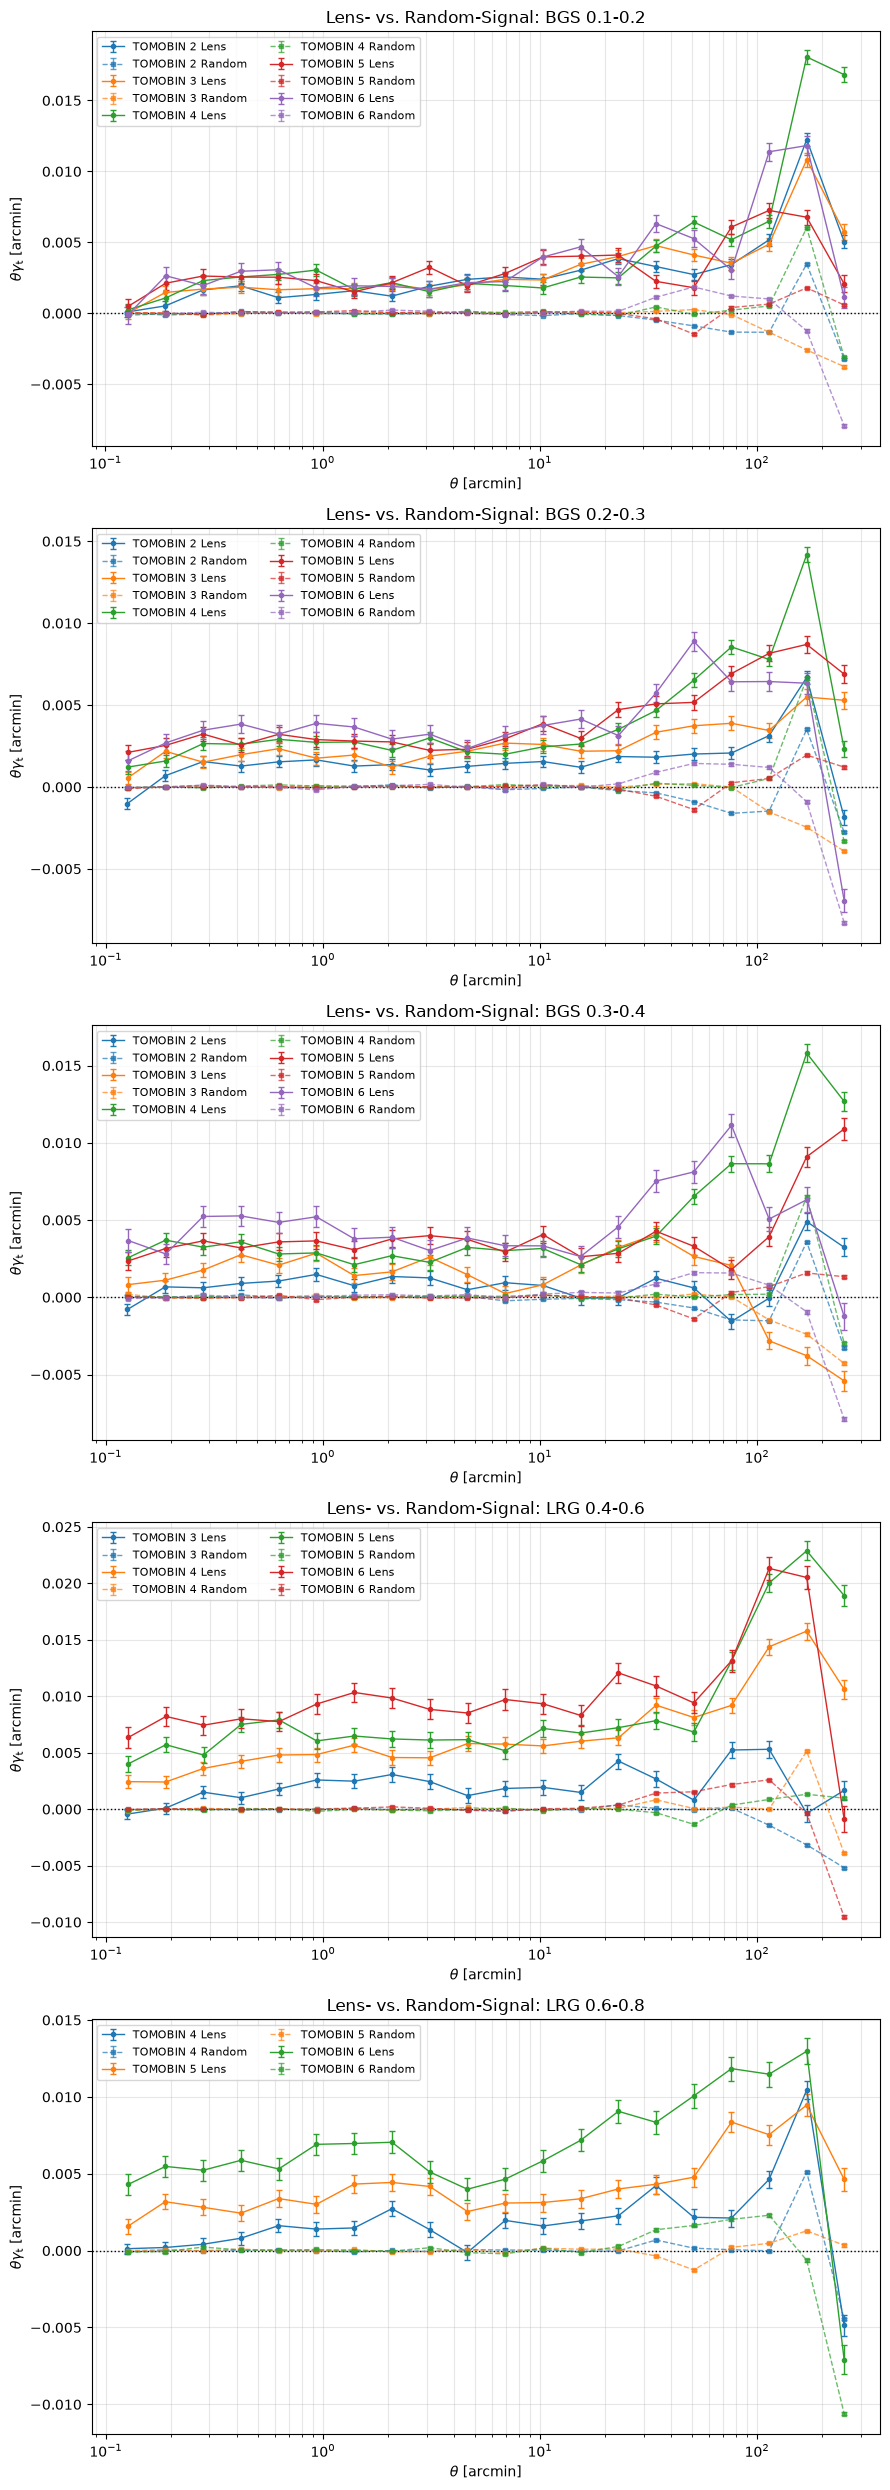

In [47]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Mean-Shear <e1>, <e2> pro KiDS Source-TOMOBIN
#
#    Ein Mean-Shear != 0 (additiver Bias) erzeugt um jede
#    Lens-/Random-Verteilung ein Scheinsignal.
#    Gewichteter Mittelwert, Fehler aus der gewichteten Streuung.
# ============================================================

print("=" * 85)
print("Mean-Shear pro Source-TOMOBIN (gewichtet)")
print("=" * 85)
print(
    f"{'TOMOBIN':>7s} {'N':>12s} "
    f"{'<e1>':>11s} {'err':>10s} {'sig':>6s} "
    f"{'<e2>':>11s} {'err':>10s} {'sig':>6s}"
)

mean_shear = {}

for source_bin, df in kids_tomo_dfs.items():

    w = df["weight"].to_numpy(dtype=np.float64)
    e1 = df["e1"].to_numpy(dtype=np.float64)
    e2 = df["e2"].to_numpy(dtype=np.float64)

    valid = np.isfinite(w) & np.isfinite(e1) & np.isfinite(e2)
    w, e1, e2 = w[valid], e1[valid], e2[valid]

    sum_w = np.sum(w)

    m1 = np.sum(w * e1) / sum_w
    m2 = np.sum(w * e2) / sum_w

    err1 = np.sqrt(np.sum(w**2 * (e1 - m1) ** 2)) / sum_w
    err2 = np.sqrt(np.sum(w**2 * (e2 - m2) ** 2)) / sum_w

    mean_shear[source_bin] = (m1, err1, m2, err2)

    print(
        f"{source_bin:7d} {len(w):12,d} "
        f"{m1:11.2e} {err1:10.1e} {abs(m1) / err1:6.1f} "
        f"{m2:11.2e} {err2:10.1e} {abs(m2) / err2:6.1f}"
    )

print("\n'sig' = |Mean| / Fehler. Werte >> 3 deuten auf additiven Bias hin.")


# ============================================================
# 2. Vergleich gamma_t,rand mit gamma_t,lens bei gleichem theta
#
#    gamma_t,lens = ng.xi (ohne Random-Subtraktion)
#    gamma_t,rand = rg.xi
#
#    Verhältnis |gamma_t,rand| / |gamma_t,lens| pro Radiusbin und
#    als Summe über alle Bins. Zusätzlich: Signifikanz des
#    Random-Signals relativ zum Lens-Fehler.
# ============================================================

print("\n")
print("=" * 95)
print("Random- vs. Lens-Signal")
print("=" * 95)
print(
    f"{'Lens':14s} {'Source':>6s} "
    f"{'sum|rand|/sum|lens|':>20s} "
    f"{'median Verh.':>13s} "
    f"{'max Verh.':>10s} "
    f"{'rand/err_lens (rms)':>20s}"
)

ratio_results = {}

for (lens_name, source_bin), result in ggl_results.items():

    r, _, _, _, ng, rg = result

    lens_t = ng.xi
    rand_t = rg.xi
    lens_err = np.sqrt(ng.varxi)

    valid = np.isfinite(lens_t) & np.isfinite(rand_t) & (lens_t != 0)

    ratio = np.abs(rand_t) / np.abs(lens_t)
    ratio[~valid] = np.nan

    total_ratio = (
        np.sum(np.abs(rand_t[valid])) / np.sum(np.abs(lens_t[valid]))
    )

    rand_over_err = rand_t[valid] / lens_err[valid]
    rms_sig = np.sqrt(np.mean(rand_over_err**2))

    ratio_results[(lens_name, source_bin)] = {
        "r": r,
        "ratio": ratio,
        "total_ratio": total_ratio,
        "rms_sig": rms_sig,
    }

    print(
        f"{lens_name:14s} {source_bin:6d} "
        f"{total_ratio:20.3f} "
        f"{np.nanmedian(ratio):13.3f} "
        f"{np.nanmax(ratio):10.2f} "
        f"{rms_sig:20.2f}"
    )

print(
    "\nInterpretation: sum|rand|/sum|lens| << 1 -> unkritisch. "
    "rand/err_lens (rms) ~ 1 -> Random-Signal liegt im Rauschen "
    "des Lens-Signals."
)


# ============================================================
# 3. Plot: gamma_t,lens und gamma_t,rand direkt übereinander
# ============================================================

lens_names = list(dict.fromkeys(k[0] for k in ggl_results))
n_rows = len(lens_names)

fig, axes = plt.subplots(
    n_rows,
    1,
    figsize=(9, 5 * n_rows),
    squeeze=False,
)

for ax, lens_name in zip(axes[:, 0], lens_names):

    for color_index, ((name, source_bin), result) in enumerate(
        (k, v) for k, v in ggl_results.items() if k[0] == lens_name
    ):

        r, _, _, _, ng, rg = result
        color = f"C{color_index}"

        ax.errorbar(
            r,
            r * ng.xi,
            yerr=r * np.sqrt(ng.varxi),
            color=color,
            marker="o",
            markersize=3,
            linewidth=1,
            capsize=2,
            label=f"TOMOBIN {source_bin} Lens",
        )

        ax.errorbar(
            r,
            r * rg.xi,
            yerr=r * np.sqrt(rg.varxi),
            color=color,
            marker="s",
            markersize=3,
            linestyle="--",
            linewidth=1,
            capsize=2,
            alpha=0.7,
            label=f"TOMOBIN {source_bin} Random",
        )

    ax.axhline(0, linestyle=":", linewidth=1, color="k")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\theta$ [arcmin]")
    ax.set_ylabel(r"$\theta\gamma_{\rm t}$ [arcmin]")
    ax.set_title(f"Lens- vs. Random-Signal: {lens_name}")
    ax.grid(True, which="both", linestyle="-", alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

Gesamtbild: Das Ergebnis ist gut. Das Random-Signal ist klein gegen das Lens-Signal, und ein additiver Shear-Bias ist ausgeschlossen. Die Subtraktion ist eine kleine Korrektur.

1. Mean-Shear

e1 und e2 liegen bei etwa 10⁻⁵ bis 5·10⁻⁵, die Fehler bei etwa 1.5–2.4·10⁻⁴. Die Signifikanz sig ist überall ≤ 0.3, also weit unter 3.
Es gibt keinen additiven Bias (c-Term) in e1/e2.

2. Random- vs. Lens-Signal

sum|rand|/sum|lens|: Der Wert liegt zwischen 0.006 und 0.077, also bei etwa 1–8 %. Das Random-Signal ist ein kleiner Bruchteil des Lens-Signals und damit unkritisch.
Median-Verhältnis: Es liegt bei etwa 1–6 %, in einem Fall bei 17 % (BGS 0.3–0.4/TOMOBIN 2).
Max-Verhältnis: Die Ausreißer (263, 27, 10 usw.) kannst du ignorieren. Sie entstehen in einzelnen Bins, in denen das Lens-Signal nahe 0 ist, und teilen dann durch fast nichts.
rand/err_lens (rms): Die Werte liegen bei etwa 0.7 bis 3.6, typisch bei 2–3. Das Random-Signal ist also etwa 2–3× größer als der Lens-Fehler. Das ist wieder der Effekt aus dem χ²-Test: Der Fehler varxi enthält nur Shape-Noise. Bei höherem Signal-zu-Rausch-Verhältnis, wie bei den niedrigen Source-Bins, steigt der Wert. Bei den hohen Source-Bins (5, 6), wo das Signal rauschiger ist, liegt er näher an 1.
Schluss

Der Null-Test ist formal nicht bestanden, weil die Fehler zu klein sind. Physikalisch ist das Random-Signal aber nur wenige Prozent des Lens-Signals, und es gibt keinen Mean-Shear-Bias.
Das spricht für Restrauschen durch Footprint und Randeffekte sowie unterschätzte Fehler, nicht für einen groben Fehler.
Die Subtraktion ist sinnvoll und korrigiert diese Restsignale. Für belastbare Fehler brauchst du eine Jackknife-Kovarianz (TreeCorr npatch).

# Calculate Boost-Factor

Boost-Faktor b(theta)
Lens           Source  b(kleinstes theta)  b(größtes theta)   mean b    max b
BGS 0.1-0.2         2              0.9554            1.0162   1.0004   1.0162
BGS 0.1-0.2         3              0.9176            1.0177   0.9967   1.0177
BGS 0.1-0.2         4              0.8110            1.0175   0.9862   1.0175
BGS 0.1-0.2         5              0.7588            1.0166   0.9792   1.0166
BGS 0.1-0.2         6              0.6790            1.0176   0.9803   1.0180
BGS 0.2-0.3         2              1.1820            1.0000   1.0399   1.1820
BGS 0.2-0.3         3              1.0437            1.0013   1.0121   1.0480
BGS 0.2-0.3         4              0.8780            0.9986   0.9894   1.0005
BGS 0.2-0.3         5              0.8399            0.9979   0.9873   1.0014
BGS 0.2-0.3         6              0.7743            0.9967   0.9864   1.0143
BGS 0.3-0.4         2              1.5435            0.9908   1.0988   1.5435
BGS 0.3-0.4         3              1.1074 

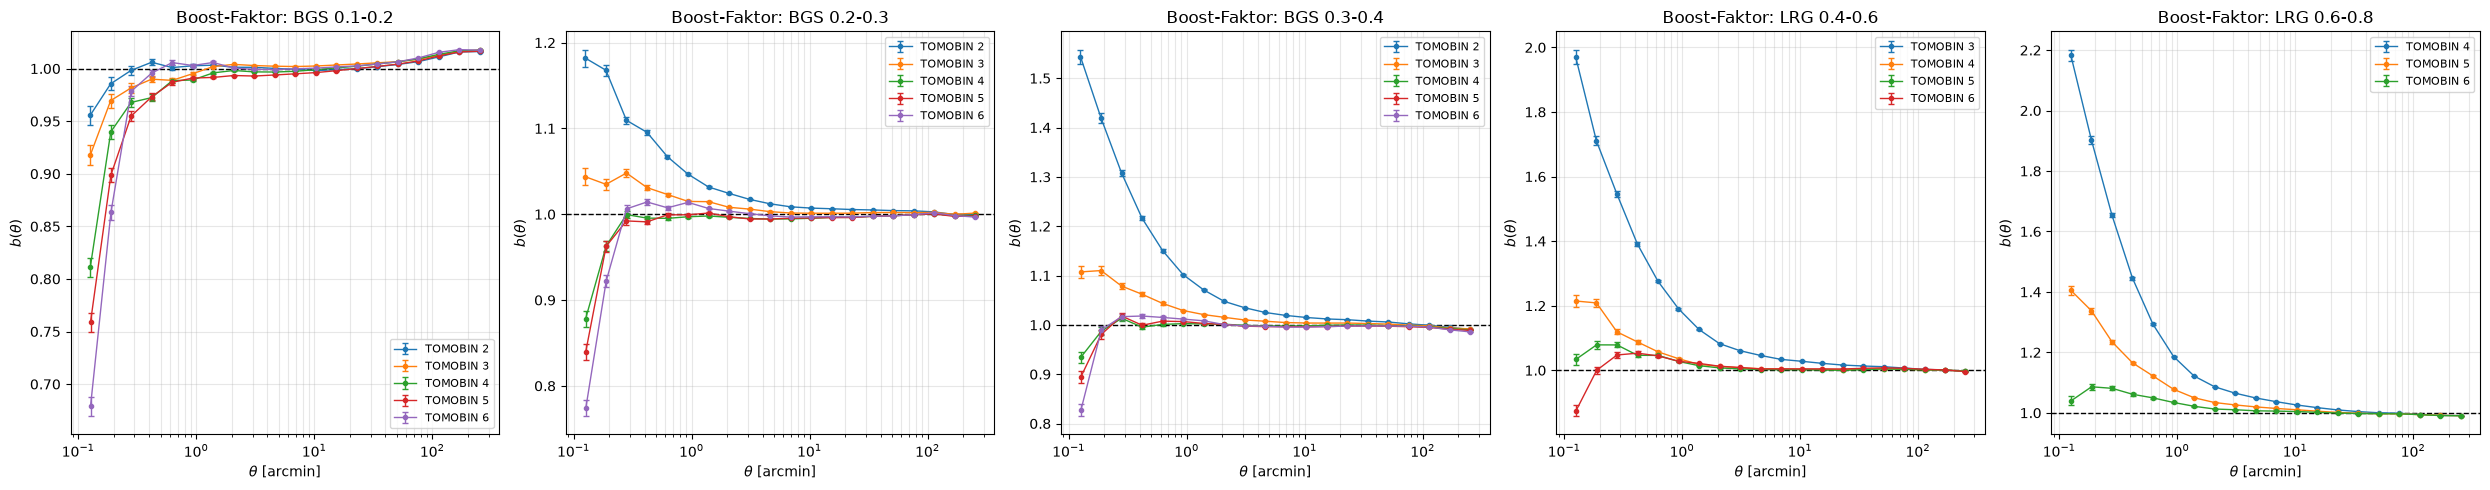

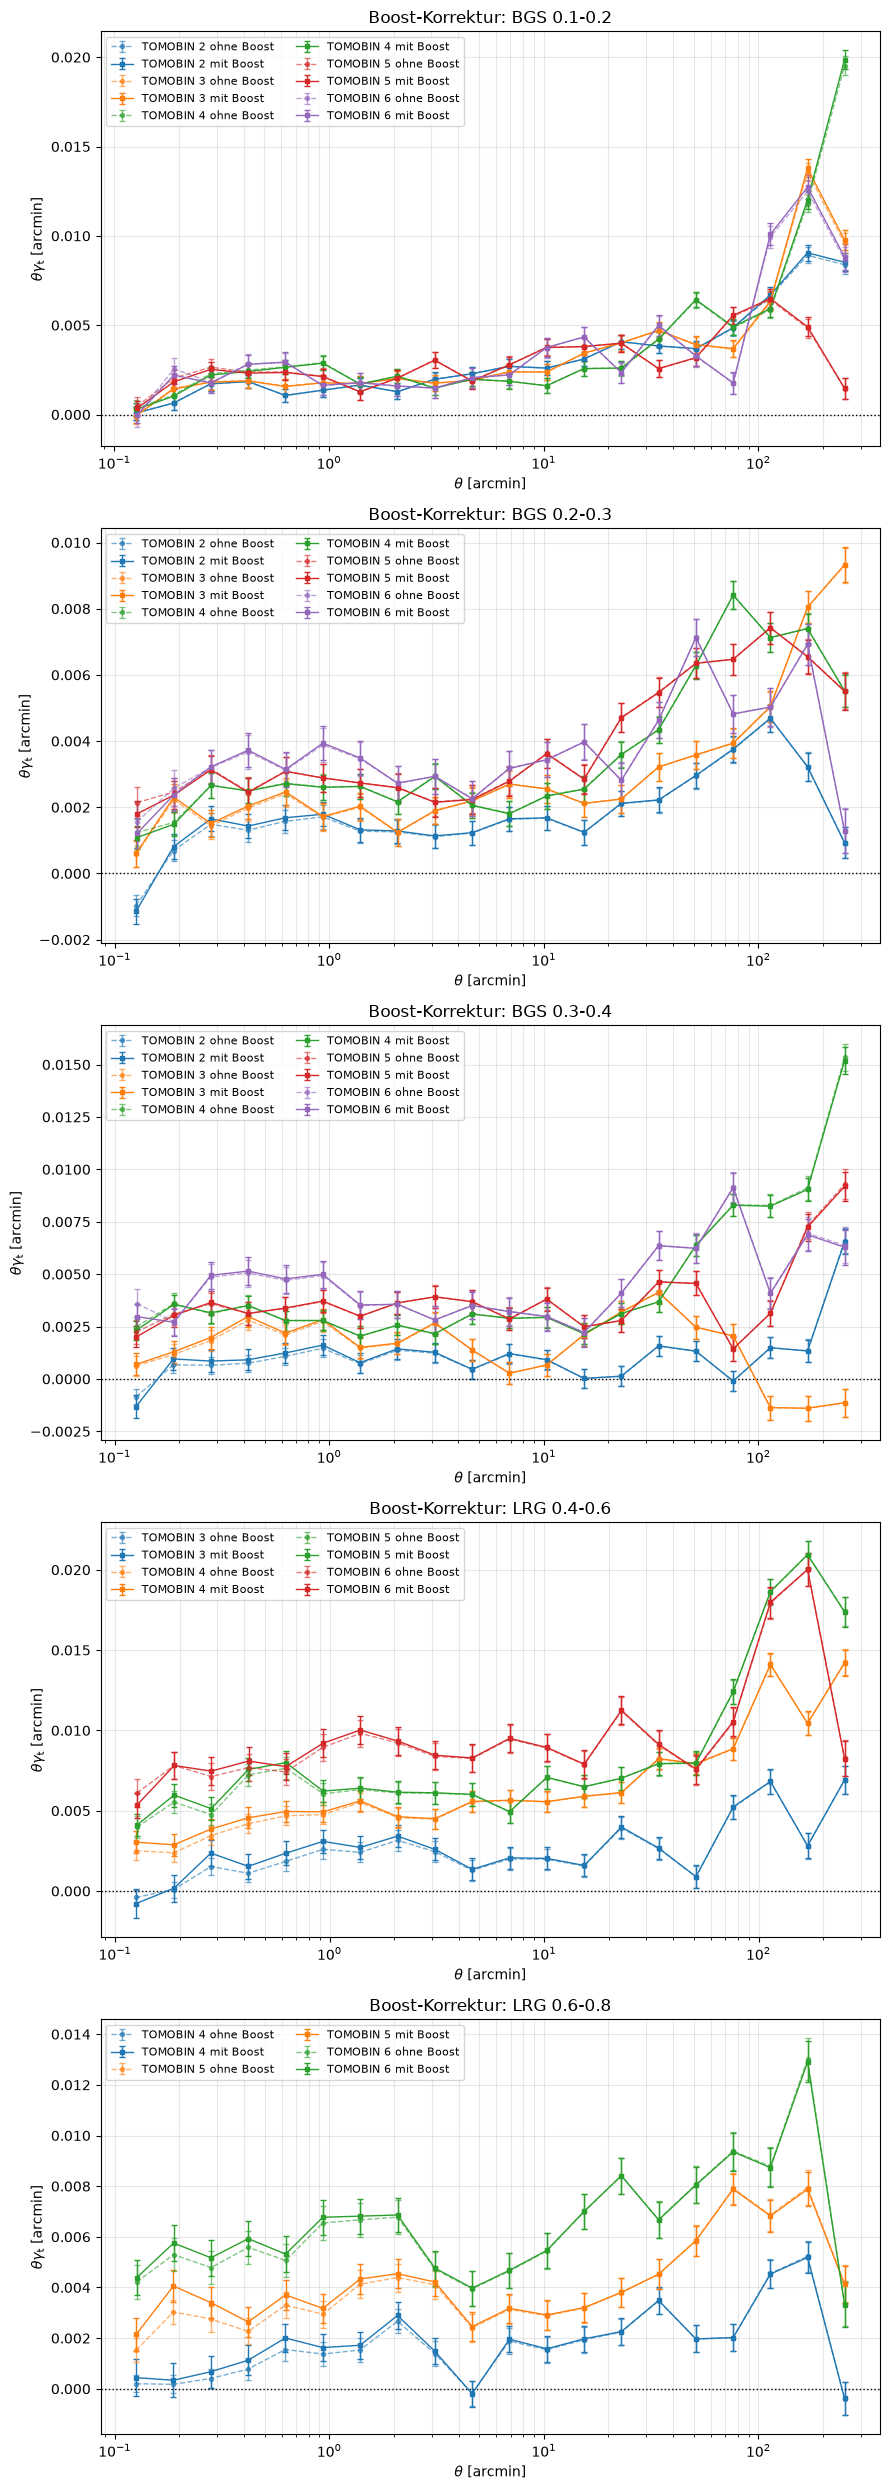

In [48]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Boost-Faktor
#
#     b(theta) = [ sum_w(Lens-Source-Paare) / sum_w(Lenses) ]
#                -------------------------------------------
#                [ sum_w(Rand-Source-Paare) / sum_w(Randoms) ]
#
# - ng.weight bzw. rg.weight = Summe der Paargewichte pro
#   Radiusbin (hier: KiDS-Quellgewichte, da Lenses/Randoms
#   ungewichtet sind).
# - Normierung auf die Gewichtssumme der Lens- bzw. Random-Kataloge,
#   da es sehr viel mehr Randoms als Lenses gibt.
#
# Korrigiertes Signal:
#
#     gamma_t,corr = b * (gamma_t,lens - gamma_t,rand)
#
# Fehler von b: Poisson-Näherung über die Paaranzahl,
#     (sigma_b / b)^2 = 1/N_pairs,lens + 1/N_pairs,rand
# ============================================================

all_lens_cats = {**bgs_lens_cats, **lrg_lens_cats}
all_random_cats = {**bgs_random_cats, **lrg_random_cats}

boost_results = {}

print("=" * 85)
print("Boost-Faktor b(theta)")
print("=" * 85)
print(
    f"{'Lens':14s} {'Source':>6s} "
    f"{'b(kleinstes theta)':>19s} "
    f"{'b(größtes theta)':>17s} "
    f"{'mean b':>8s} {'max b':>8s}"
)

for (lens_name, source_bin), result in ggl_results.items():

    r, gammat_sub, gammax_sub, sigma_sub, ng, rg = result

    sumw_lens = all_lens_cats[lens_name].sumw
    sumw_rand = all_random_cats[lens_name].sumw

    pairs_lens = ng.weight / sumw_lens
    pairs_rand = rg.weight / sumw_rand

    valid = (pairs_rand > 0) & (pairs_lens > 0)

    boost = np.full_like(pairs_lens, np.nan, dtype=np.float64)
    boost[valid] = pairs_lens[valid] / pairs_rand[valid]

    boost_err = np.full_like(boost, np.nan)
    boost_err[valid] = boost[valid] * np.sqrt(
        1.0 / ng.npairs[valid] + 1.0 / rg.npairs[valid]
    )

    # Boost-korrigiertes Signal (Randoms bereits subtrahiert)
    gammat_corr = boost * gammat_sub
    gammat_corr_err = boost * sigma_sub

    boost_results[(lens_name, source_bin)] = {
        "r": r,
        "boost": boost,
        "boost_err": boost_err,
        "gammat_corr": gammat_corr,
        "gammat_corr_err": gammat_corr_err,
    }

    print(
        f"{lens_name:14s} {source_bin:6d} "
        f"{boost[valid][0]:19.4f} "
        f"{boost[valid][-1]:17.4f} "
        f"{np.nanmean(boost):8.4f} "
        f"{np.nanmax(boost):8.4f}"
    )

print(
    "\nb = 1: kein Überschuss an Quellen um Lenses. "
    "b > 1: Überschuss (v.a. auf kleinen Skalen erwartet)."
)


# ============================================================
# Plot 1: Boost-Faktor b(theta)
# ============================================================

lens_names = list(dict.fromkeys(k[0] for k in boost_results))

fig, axes = plt.subplots(
    1,
    len(lens_names),
    figsize=(5 * len(lens_names), 5),
    squeeze=False,
)

for ax, lens_name in zip(axes[0], lens_names):

    for (name, source_bin), res in boost_results.items():

        if name != lens_name:
            continue

        ax.errorbar(
            res["r"],
            res["boost"],
            yerr=res["boost_err"],
            marker="o",
            markersize=3,
            linewidth=1,
            capsize=2,
            label=f"TOMOBIN {source_bin}",
        )

    ax.axhline(1, linestyle="--", linewidth=1, color="k")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\theta$ [arcmin]")
    ax.set_ylabel(r"$b(\theta)$")
    ax.set_title(f"Boost-Faktor: {lens_name}")
    ax.grid(True, which="both", linestyle="-", alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: theta * gamma_t mit und ohne Boost-Korrektur
#         (Randoms in beiden Fällen subtrahiert)
# ============================================================

fig, axes = plt.subplots(
    len(lens_names),
    1,
    figsize=(9, 5 * len(lens_names)),
    squeeze=False,
)

for ax, lens_name in zip(axes[:, 0], lens_names):

    color_index = 0

    for (name, source_bin), res in boost_results.items():

        if name != lens_name:
            continue

        r = res["r"]
        _, gammat_sub, _, sigma_sub, _, _ = ggl_results[(name, source_bin)]
        color = f"C{color_index}"
        color_index += 1

        ax.errorbar(
            r,
            r * gammat_sub,
            yerr=r * sigma_sub,
            color=color,
            marker="o",
            markersize=3,
            linestyle="--",
            linewidth=1,
            capsize=2,
            alpha=0.6,
            label=f"TOMOBIN {source_bin} ohne Boost",
        )

        ax.errorbar(
            r,
            r * res["gammat_corr"],
            yerr=r * res["gammat_corr_err"],
            color=color,
            marker="s",
            markersize=3,
            linestyle="-",
            linewidth=1,
            capsize=2,
            label=f"TOMOBIN {source_bin} mit Boost",
        )

    ax.axhline(0, linestyle=":", linewidth=1, color="k")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\theta$ [arcmin]")
    ax.set_ylabel(r"$\theta\gamma_{\rm t}$ [arcmin]")
    ax.set_title(f"Boost-Korrektur: {lens_name}")
    ax.grid(True, which="both", linestyle="-", alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

The boost factor does not appear to have a significant effect on the shear signal, since mean(b) is close to 1. The boost factor plots look similar to those in the paper.